# 第三章 · 简单线性回归：系数估计与置信区间

作者：林泓浩。配套《零基础统计学习指南》。本 Notebook 截止斜率置信区间，不含假设检验。

从上到下运行全部代码块；数据为虚构教学数据，无须联网下载。请在本文件所在的第三章目录运行，图片写入其“图片”文件夹。需要 NumPy、Matplotlib、SciPy 和 IPython。理论假设与完整推导见讲义。

## 代码 3.1.1-01 · 创建三个市场的教学数据

In [2]:
import numpy as np

x = np.array([1.0, 2.0, 3.0])
y = np.array([2.0, 3.0, 5.0])
print("x:", x)
print("y:", y)
print("shapes:", x.shape, y.shape)


x: [1. 2. 3.]
y: [2. 3. 5.]
shapes: (3,) (3,)


**逐步读代码**

- `import numpy as np` 导入 NumPy，用简短名称 `np` 调用。`np.array` 把列表转换为可逐元素计算的数组；小数写法使本例使用浮点数。

- `x` 是三个市场的广告预算，单位为千元；`y` 是对应销量，单位为千件。同一位置的两个数构成一个样本。这里是虚构教学数据，不是教材 Advertising 数据集。

- 两个数组的 `shape` 都是 `(3,)`，表示有三个元素的一维数组。这里手算单特征公式，用一维数组即可；不要与某些模型接口要求的二维特征矩阵混淆。`print` 显示括号中的内容。

## 代码 3.1.1-02 · 计算均值并中心化

In [3]:
x_mean = x.mean()
y_mean = y.mean()
x_centered = x - x_mean
y_centered = y - y_mean
print("means:", x_mean, y_mean)
print("x_centered:", x_centered)
print("y_centered:", y_centered)
print("centered sums:", x_centered.sum(), y_centered.sum())


means: 2.0 3.3333333333333335
x_centered: [-1.  0.  1.]
y_centered: [-1.333333 -0.333333  1.666667]
centered sums: 0.0 -4.440892098500626e-16


**逐步读代码**

- `.mean()` 对数组元素求算术平均，得到一个数。`x_mean` 是 2，`y_mean` 是 10/3 的浮点近似。

- 数组减去一个数时，NumPy 将这个数作用到每个元素，这叫广播。中心化后仍是形状 `(3,)` 的数组，记录每个观测值偏离均值多少。

- `.sum()` 求元素总和。理论上中心化后的和为零；浮点运算可能显示约 10 的负 16 次方量级的小数，它是数值舍入误差，不是公式失效。

## 代码 3.1.1-03 · 把两个求和式翻译为 NumPy

In [4]:
Sxx = np.sum(x_centered ** 2)
Sxy = np.sum(x_centered * y_centered)
print("Sxx:", Sxx)
print("Sxy:", Sxy)


Sxx: 2.0
Sxy: 3.0


**逐步读代码**

- `** 2` 先对每个元素平方，`np.sum` 再把平方值加起来。因此第一行计算的是离差平方和，不是先求和再平方。

- `x_centered * y_centered` 对应位置逐元素相乘，结果仍是 `(3,)`；外层 `np.sum` 将三个乘积相加，得到一个数。两个数组都中心化了，但乘积之和不必为零。

- `Sxx` 与 `Sxy` 是变量名，大小写必须前后一致。本例得到 2 和 3，分别对应数学公式中的输入离差平方和与交叉离差和。

## 代码 3.1.1-04 · 计算最小二乘斜率与截距

In [5]:
beta1_hat = Sxy / Sxx
beta0_hat = y_mean - beta1_hat * x_mean
print("slope:", beta1_hat)
print("intercept:", beta0_hat)


slope: 1.5
intercept: 0.3333333333333335


**逐步读代码**

- 第一行将交叉离差和除以输入离差平方和。前面已经确认 `Sxx = 2 > 0`，所以本例可以使用这个公式；若所有预算相同，就不能直接相除。

- 第二行先计算斜率乘以预算均值，再从销量均值中减去它。变量名中的 `hat` 对应数学记号中的帽子，表示数据算出的估计值。

- 输出的斜率为 1.5，截距为 1/3 的浮点近似。斜率单位是千件/千元，截距单位是千件。

## 代码 3.1.1-05 · 预测训练样本并计算残差

In [6]:
y_fit = beta0_hat + beta1_hat * x
residual = y - y_fit
print("fitted values:", y_fit)
print("residuals:", residual)
print("residual shape:", residual.shape)


fitted values: [1.833333 3.333333 4.833333]
residuals: [ 0.166667 -0.333333  0.166667]
residual shape: (3,)


**逐步读代码**

- `beta1_hat * x` 把斜率分别乘以三个预算，随后广播加上截距，所以 `y_fit` 是三个训练样本的拟合值，形状为 `(3,)`。

- `y - y_fit` 按同一位置相减，使用的约定始终是实际值减预测值。正残差表示低估，负残差表示高估。

- 这里的残差可以计算，因为这三个样本的真实观测销量已经知道；模型误差项涉及未知的真实回归函数，不能直接与残差画等号。

## 代码 3.1.1-06 · 计算残差平方和与训练 MSE

In [7]:
squared_residual = residual ** 2
rss = np.sum(squared_residual)
train_mse = np.mean(squared_residual)
print("squared residuals:", squared_residual)
print("RSS:", rss)
print("training MSE:", train_mse)
print("square of residual sum:", residual.sum() ** 2)


squared residuals: [0.027778 0.111111 0.027778]
RSS: 0.16666666666666652
training MSE: 0.055555555555555504
square of residual sum: 7.888609052210118e-31


**逐步读代码**

- `squared_residual` 保存逐个残差的平方；`np.sum` 给出 RSS，`np.mean` 给出训练 MSE，后者等于前者除以三个样本。

- 最后一行故意先求残差和再平方，用来对比两种运算。它不是 RSS：正负残差会相互抵消。

- 本例 RSS 为 1/6，训练 MSE 为 1/18。最后一行接近零，只能说明残差和接近零，不能说明每个预测都准确。

## 代码 3.1.1-07 · 对一个新预算作预测

In [8]:
x_new = 4.0
y_new_pred = beta0_hat + beta1_hat * x_new
print("new budget:", x_new)
print("predicted sales:", y_new_pred)


new budget: 4.0
predicted sales: 6.333333333333334


**逐步读代码**

- `x_new` 是一个数，表示新预算为 4 千元；代入已拟合的直线，得到一个预测数值，约为 6.3333 千件。

- 使用新变量 `y_new_pred`，保留前面的训练拟合数组 `y_fit`，方便后续继续计算残差和标准误。

- 4 超出了训练预算范围 1 到 3，这属于外推。公式可以输出数值，但外推是否可靠需要额外判断。没有新市场实际销量，就不能计算它的残差。

## 代码 3.1.1-08 · 画出观测点与拟合直线

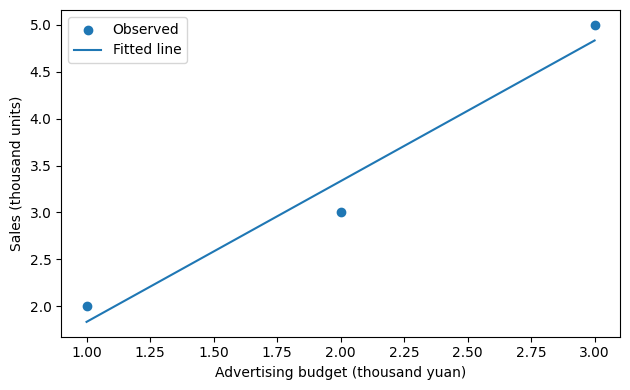

In [9]:
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display

image_dir = Path("图片")
image_dir.mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.scatter(x, y, label="Observed")
ax.plot(x, y_fit, label="Fitted line")
ax.set_xlabel("Advertising budget (thousand yuan)")
ax.set_ylabel("Sales (thousand units)")
ax.legend()
fig.tight_layout()
fig.savefig(image_dir / "311-fit.png", dpi=180)
fig.savefig(image_dir / "311-fit.pdf")
display(fig)
plt.close(fig)


**逐步读代码**

- `Path` 管理文件路径；`Path("图片")` 表示工作目录下的图片文件夹。`mkdir(exist_ok=True)` 是路径对象的方法，创建目录，目录已存在时允许继续。请在第三章 Notebook 所在目录运行。

- `plt.subplots` 创建整张画布 `fig` 和绘图区域 `ax`；`figsize` 以英寸指定宽和高。尺寸是可复用的显示设置，不需要背诵。

- `scatter(x, y)` 画实际观测点；`plot(x, y_fit)` 依输入顺序连接拟合值。本例 `x` 已从小到大排列，且拟合值位于同一直线上；实际销量连起来并不等于拟合直线。

- `label` 为图例提供名称；`set_xlabel`、`set_ylabel` 设置坐标轴标题和单位；`legend()` 显示图例。这里使用默认颜色，不需要记忆颜色编码。

- `tight_layout()` 调整边距；路径对象之间的 `/` 拼接文件路径。`savefig` 保存 PNG 和矢量 PDF，`dpi=180` 设置 PNG 分辨率。

- `display(fig)` 在 Notebook 中显示图片，`plt.close(fig)` 关闭后台画布以避免重复显示，已保存的图片和已经显示的输出仍保留。

## 代码 3.1.2-01 · 同一个真实模型可以产生不同的拟合直线

In [10]:
true_mean = 2.0 + 3.0 * x
error_a = np.array([-1.0, 0.0, 1.0])
error_b = np.array([1.0, 0.0, -1.0])

for name, errors in [("A", error_a), ("B", error_b)]:
    y_case = true_mean + errors
    slope_case = np.sum(x_centered * (y_case - y_case.mean())) / Sxx
    intercept_case = y_case.mean() - slope_case * x_mean
    rss_case = np.sum((y_case - (intercept_case + slope_case * x)) ** 2)
    print(name, "sales:", y_case)
    print("slope, intercept, RSS:", slope_case, intercept_case, rss_case)


A sales: [ 4.  8. 12.]
slope, intercept, RSS: 4.0 0.0 0.0
B sales: [ 6.  8. 10.]
slope, intercept, RSS: 2.0 4.0 0.0


**逐步读代码**

- `true_mean` 设置这个新例子的真实平均销量为 2 加 3 倍预算。两组误差是人为指定的示意取值，没有执行随机抽样，也不是声称三点足以验证分布假设。

- 方括号里有两个二元组，分别包含组名和误差数组。`for name, errors in ...` 每次取一组，并把两个内容分别赋给 `name` 与 `errors`；缩进部分每组执行一次。

- `y_case` 是真实均值加上这组误差。随后使用已经推导的相同公式计算本组斜率、截距和 RSS。

- 后缀 `_case` 避免覆盖最初数据的 `beta1_hat`、`beta0_hat`、`y` 和 `residual`，后面的置信区间仍针对最初三个市场。

- 两组 RSS 都为零，斜率却分别为 4 和 2，都不同于真实斜率 3。训练集拟合完美不能保证参数估计准确。

## 代码 3.1.2-02 · 准备噪声方差估计的分子和自由度

In [11]:
n = len(y)
residual_df = n - 2
rss = np.sum(residual ** 2)
print("n:", n)
print("residual degrees of freedom:", residual_df)
print("RSS:", rss)


n: 3
residual degrees of freedom: 1
RSS: 0.16666666666666652


**逐步读代码**

- `len(y)` 返回观测销量的数量，本例为 3。`residual_df = n - 2` 是带截距、单一斜率且输入有变化的模型对应的残差自由度，本例为 1。

- `rss` 重新由最初三个市场的残差计算；不是前一个示意例子的 `rss_case`。

- 使用这个方差估计式之前，需要样本量大于 2、输入离差平方和大于零，以及正文给出的零均值、同方差、不相关误差条件。

## 代码 3.1.2-03 · 计算噪声方差、RSE 和斜率标准误

In [12]:
sigma2_hat = rss / residual_df
rse = np.sqrt(sigma2_hat)
slope_se = rse / np.sqrt(Sxx)
print("estimated noise variance:", sigma2_hat)
print("RSE:", rse)
print("estimated slope SE:", slope_se)


estimated noise variance: 0.16666666666666652
RSE: 0.40824829046386285
estimated slope SE: 0.28867513459481275


**逐步读代码**

- `sigma2_hat` 是 RSS 除以残差自由度，估计真实噪声方差；不要把分母改成 `n`，那样得到的是训练 MSE。

- `np.sqrt` 求平方根；`rse` 是残差标准误，用来估计销量噪声的标准差，单位为千件。方差估计无偏并不意味着开方后的 RSE 也无偏。

- `slope_se` 再除以输入离差平方和的平方根，估计斜率估计量的标准差，单位为千件/千元。它不是下一次销量预测误差，也不是斜率估计误差的绝对上界。

## 代码 3.1.2-04 · 用 t 分布求双侧区间的临界值

In [13]:
from scipy.stats import t

alpha = 0.05
left_probability = 1 - alpha / 2
critical_value = t.ppf(left_probability, df=residual_df)
print("alpha:", alpha)
print("left cumulative probability:", left_probability)
print("critical value:", critical_value)


alpha: 0.05
left cumulative probability: 0.975
critical value: 12.706204736432095


**逐步读代码**

- `from scipy.stats import t` 导入 t 分布工具。这里 `t` 是计算概率分布的对象，不是从样本算出的统计量数值。

- `alpha = 0.05` 表示区间方法未覆盖真参数的总概率为 5%；双侧等尾区间每侧分配一半，因此右端临界值左边累计概率是 `1 - alpha / 2 = 0.975`。

- `ppf` 是分位数函数：给定左侧累计概率，返回对应横坐标。`df` 是自由度参数，使用前面算出的 `residual_df = 1`。

- 输出约 12.7062，大于标准正态的 1.96。这是自由度很小时 t 分布尾部更厚的体现；精确覆盖率依赖正文的正态误差假设。

## 代码 3.1.2-05 · 构造并解释斜率的 95% 置信区间

In [14]:
margin = critical_value * slope_se
ci_lower = beta1_hat - margin
ci_upper = beta1_hat + margin
print("estimated slope:", beta1_hat)
print("margin:", margin)
print("95% interval:", ci_lower, ci_upper)


estimated slope: 1.5
margin: 3.6679653624787822
95% interval: -2.1679653624787822 5.167965362478782


**逐步读代码**

- `margin` 是临界值乘以估计标准误，表示区间的半宽。它不是预测残差，也不是一次估计误差的已知大小。

- `ci_lower` 与 `ci_upper` 分别将半宽从斜率估计值中减去、加上，得到下端点和上端点。

- 区间约为 [-2.168, 5.168]。点估计虽然为正，但这份数据给出的区间很宽；不能仅凭正的点估计就断言斜率稳定地为正。

- 95% 指相同设计与模型条件下，重复抽样、重复构造区间的长期覆盖比例；观测数据给定后，本次区间端点已经固定。

## 代码 3.1.2-06 · 比较不同置信水平的区间宽度

In [15]:
for confidence in [0.90, 0.95, 0.99]:
    alpha_level = 1 - confidence
    critical = t.ppf(1 - alpha_level / 2, df=residual_df)
    half_width = critical * slope_se
    lower = beta1_hat - half_width
    upper = beta1_hat + half_width
    print(f"confidence={confidence:.0%}: [{lower:.3f}, {upper:.3f}]")


confidence=90%: [-0.323, 3.323]
confidence=95%: [-2.168, 5.168]
confidence=99%: [-16.876, 19.876]


**逐步读代码**

- `for` 循环依次取三个置信水平；每一次都用同一份数据、同一个斜率估计和同一个标准误，只改变区间的覆盖目标。

- `alpha_level` 是一减置信水平；依次计算对应分位数、半宽和端点，与上一块代码的步骤一致。

- `f"..."` 是格式化字符串：花括号中写变量，`:.0%` 把小数显示成不带小数位的百分数，`:.3f` 保留三位小数。这只改变显示方式，没有把计算中的数值提前截断。

- 置信水平升高，临界值和区间宽度增大。覆盖目标更高不等于估计更精确；输出格式可以查阅复用，理解区间计算才是核心。

---

# 后续整理：斜率检验、模型评估与多元回归

原有代码和说明保留。以下追加至 3.3.3；公式编号与本次 PDF 一致。

## 前置公式索引

以下保留与 PDF 相同的公式编号，供新增推导回指。完整的前置推导见同目录《第三章_学习笔记与实验_至3.3.3.ipynb》。

<a id="ref-eq-prior-sections-3-1-001"></a>

$$
\mathbb E[Y\mid X=x]=\beta_0+\beta_1x,
\qquad Y=\beta_0+\beta_1X+\varepsilon,
\qquad\mathbb E[\varepsilon\mid X]=0.
\tag{3.1}
$$

<a id="ref-eq-prior-sections-3-1-002"></a>

$$
\widehat y(x)=\widehat\beta_0+\widehat\beta_1x
\tag{3.2}
$$

<a id="ref-eq-prior-sections-3-1-1-001"></a>

$$
r_i(b_0,b_1)=y_i-(b_0+b_1x_i).
\tag{3.3}
$$

<a id="ref-eq-prior-sections-3-1-1-002"></a>

$$
Q(b_0,b_1)=\operatorname{RSS}(b_0,b_1)
=\sum_{i=1}^n[y_i-(b_0+b_1x_i)]^2.
\tag{3.4}
$$

<a id="ref-eq-prior-sections-3-1-1-003"></a>

$$
(\widehat\beta_0,\widehat\beta_1)
=\underset{(b_0,b_1)\in\mathbb R^2}{\operatorname{arg\,min}}Q(b_0,b_1).
\tag{3.5}
$$

<a id="ref-eq-prior-sections-3-1-1-017"></a>

$$
\begin{aligned}
\frac{\partial Q}{\partial b_0}
&=\sum_i 2(y_i-b_0-b_1x_i)(-1)\\
&=-2\left(\sum_i y_i-nb_0-b_1\sum_i x_i\right).
\end{aligned}
\tag{3.6}
$$

<a id="ref-eq-prior-sections-3-1-1-004"></a>

$$
n\bar y-nb_0-b_1n\bar x=0
\quad\Longrightarrow\quad b_0=\bar y-b_1\bar x.
\tag{3.7}
$$

<a id="ref-eq-prior-sections-3-1-1-018"></a>

$$
\begin{aligned}
y_i-b_0-b_1x_i
&=y_i-(\bar y-b_1\bar x)-b_1x_i\\
&=(y_i-\bar y)-b_1(x_i-\bar x).
\end{aligned}
\tag{3.8}
$$

<a id="ref-eq-prior-sections-3-1-1-005"></a>

$$
q(b_1)=Q(\bar y-b_1\bar x,b_1)
=\sum_i[(y_i-\bar y)-b_1(x_i-\bar x)]^2.
\tag{3.9}
$$

<a id="ref-eq-prior-sections-3-1-1-006"></a>

$$
S_{xx}=\sum_i(x_i-\bar x)^2,\quad
S_{xy}=\sum_i(x_i-\bar x)(y_i-\bar y),\quad
S_{yy}=\sum_i(y_i-\bar y)^2.
\tag{3.10}
$$

<a id="ref-eq-prior-sections-3-1-1-007"></a>

$$
q(b_1)=S_{yy}-2b_1S_{xy}+b_1^2S_{xx}.
\tag{3.11}
$$

<a id="ref-eq-prior-sections-3-1-1-008"></a>

$$
q'(b_1)=-2S_{xy}+2b_1S_{xx}=0
\quad\Longrightarrow\quad
\widehat\beta_1=\frac{S_{xy}}{S_{xx}}.
\tag{3.12}
$$

<a id="ref-eq-prior-sections-3-1-1-009"></a>

$$
q(b_1)=S_{xx}\left(b_1-\frac{S_{xy}}{S_{xx}}\right)^2
+S_{yy}-\frac{S_{xy}^2}{S_{xx}}.
\tag{3.13}
$$

<a id="ref-eq-prior-sections-3-1-1-010"></a>

$$
Q(b_0,b_1)\ge Q(\bar y-b_1\bar x,b_1)=q(b_1)
\ge q(\widehat\beta_1).
\tag{3.14}
$$

<a id="ref-eq-prior-sections-3-1-1-011"></a>

$$
\widehat\beta_1=\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}{\sum_i(x_i-\bar x)^2},
\qquad\widehat\beta_0=\bar y-\widehat\beta_1\bar x.
\tag{3.15}
$$

<a id="ref-eq-prior-sections-3-1-1-012"></a>

$$
\widehat y(\bar x)=\widehat\beta_0+\widehat\beta_1\bar x
=\bar y-\widehat\beta_1\bar x+\widehat\beta_1\bar x=\bar y.
\tag{3.16}
$$

<a id="ref-eq-prior-sections-3-1-1-013"></a>

$$
\sum_i e_i=\sum_i(y_i-\widehat\beta_0-\widehat\beta_1x_i)
=n(\bar y-\widehat\beta_0-\widehat\beta_1\bar x)=0.
\tag{3.17}
$$

<a id="ref-eq-prior-sections-3-1-1-014"></a>

$$
\widehat\beta_1=\frac32,\qquad\widehat\beta_0=\frac13,
\qquad\widehat y(x)=\frac13+\frac32x.
\tag{3.18}
$$

<a id="ref-eq-prior-sections-3-1-1-015"></a>

$$
(\widehat y_1,\widehat y_2,\widehat y_3)
=\left(\frac{11}{6},\frac{10}{3},\frac{29}{6}\right),
\qquad(e_1,e_2,e_3)=\left(\frac16,-\frac13,\frac16\right).
\tag{3.19}
$$

<a id="ref-eq-prior-sections-3-1-1-016"></a>

$$
\sum_i e_i^2\ne\left(\sum_i e_i\right)^2\quad\text{一般并不相等}.
\tag{3.20}
$$

<a id="ref-eq-prior-sections-3-1-2-001"></a>

$$
Y_i=\beta_0+\beta_1x_i+\varepsilon_i.
\tag{3.21}
$$

<a id="ref-eq-prior-sections-3-1-2-034"></a>

$$
\begin{aligned}
\sum_i(x_i-\bar x)(Y_i-\bar Y)
&=\sum_i(x_i-\bar x)Y_i-\bar Y\sum_i(x_i-\bar x)\\
&=\sum_i(x_i-\bar x)Y_i.
\end{aligned}
\tag{3.22}
$$

<a id="ref-eq-prior-sections-3-1-2-035"></a>

$$
\begin{aligned}
\widehat\beta_1
&=\frac{\sum_i(x_i-\bar x)(\beta_0+\beta_1x_i+\varepsilon_i)}{S_{xx}}\\
&=\frac{\beta_0\sum_i(x_i-\bar x)}{S_{xx}}
+\frac{\beta_1\sum_i(x_i-\bar x)x_i}{S_{xx}}
+\frac{\sum_i(x_i-\bar x)\varepsilon_i}{S_{xx}}.
\end{aligned}
\tag{3.23}
$$

<a id="ref-eq-prior-sections-3-1-2-002"></a>

$$
\sum_i(x_i-\bar x)x_i
=\sum_i(x_i-\bar x)^2+\bar x\sum_i(x_i-\bar x)=S_{xx}.
\tag{3.24}
$$

<a id="ref-eq-prior-sections-3-1-2-003"></a>

$$
\mathbb E[\widehat\beta_1]
=\beta_1+\sum_i a_i\mathbb E[\varepsilon_i]=\beta_1.
\tag{3.26}
$$

<a id="ref-eq-prior-sections-3-1-2-004"></a>

$$
\widehat\beta_1-\beta_1=\frac{-\varepsilon_1+\varepsilon_3}{2}.
\tag{3.27}
$$

<a id="ref-eq-prior-sections-3-1-2-005"></a>

$$
\operatorname{Var}(\varepsilon_i)=\sigma^2<\infty,
\qquad\operatorname{Cov}(\varepsilon_i,\varepsilon_j)=0\quad(i\ne j).
\tag{3.28}
$$

<a id="ref-eq-prior-sections-3-1-2-036"></a>

$$
\begin{aligned}
\operatorname{Var}(\widehat\beta_1)
&=\mathbb E\left[\left(\sum_i a_i\varepsilon_i\right)^2\right]\\
&=\sum_i a_i^2\mathbb E[\varepsilon_i^2]
+2\sum_{i<j}a_ia_j\mathbb E[\varepsilon_i\varepsilon_j].
\end{aligned}
\tag{3.29}
$$

<a id="ref-eq-prior-sections-3-1-2-006"></a>

$$
\mathbb E[\varepsilon_i\varepsilon_j]
=\operatorname{Cov}(\varepsilon_i,\varepsilon_j)
+\mathbb E[\varepsilon_i]\mathbb E[\varepsilon_j]=0.
\tag{3.30}
$$

<a id="ref-eq-prior-sections-3-1-2-007"></a>

$$
\sum_i a_i^2=\frac{\sum_i(x_i-\bar x)^2}{S_{xx}^2}
=\frac{1}{S_{xx}},
\tag{3.31}
$$

<a id="ref-eq-prior-sections-3-1-2-008"></a>

$$
\operatorname{Var}(\widehat\beta_1)=\frac{\sigma^2}{S_{xx}},
\qquad\operatorname{SE}(\widehat\beta_1)
=\sqrt{\operatorname{Var}(\widehat\beta_1)}=\frac{\sigma}{\sqrt{S_{xx}}}.
\tag{3.32}
$$

<a id="ref-eq-prior-sections-3-1-2-009"></a>

$$
\mathbb E[(\widehat\beta_1-\beta_1)^2]=\operatorname{Var}(\widehat\beta_1).
\tag{3.33}
$$

<a id="ref-eq-prior-sections-3-1-2-010"></a>

$$
z_i=x_i-\bar x,\qquad\bar\varepsilon=\frac1n\sum_i\varepsilon_i,
\qquad\delta=\widehat\beta_1-\beta_1=\frac{\sum_i z_i\varepsilon_i}{S_{xx}}.
\tag{3.34}
$$

<a id="ref-eq-prior-sections-3-1-2-011"></a>

$$
\bar Y=\beta_0+\beta_1\bar x+\bar\varepsilon.
\tag{3.35}
$$

<a id="ref-eq-prior-sections-3-1-2-037"></a>

$$
\begin{aligned}
\widehat\beta_0
&=\bar Y-\widehat\beta_1\bar x\\
&=\beta_0+\beta_1\bar x+\bar\varepsilon-(\beta_1+\delta)\bar x\\
&=\beta_0+\bar\varepsilon-\delta\bar x.
\end{aligned}
\tag{3.36}
$$

<a id="ref-eq-prior-sections-3-1-2-038"></a>

$$
\begin{aligned}
e_i&=Y_i-\widehat\beta_0-\widehat\beta_1x_i\\
&=(\beta_0+\beta_1x_i+\varepsilon_i)
-(\beta_0+\bar\varepsilon-\delta\bar x)-(\beta_1+\delta)x_i\\
&=\varepsilon_i-\bar\varepsilon-\delta z_i.
\end{aligned}
\tag{3.37}
$$

<a id="ref-eq-prior-sections-3-1-2-039"></a>

$$
\begin{aligned}
\operatorname{RSS}
&=\sum_i(\varepsilon_i-\bar\varepsilon-\delta z_i)^2\\
&=\sum_i(\varepsilon_i-\bar\varepsilon)^2
-2\delta\sum_i z_i(\varepsilon_i-\bar\varepsilon)
+\delta^2\sum_i z_i^2.
\end{aligned}
\tag{3.38}
$$

<a id="ref-eq-prior-sections-3-1-2-012"></a>

$$
\sum_i z_i(\varepsilon_i-\bar\varepsilon)
=\sum_i z_i\varepsilon_i-\bar\varepsilon\sum_i z_i
=\delta S_{xx}.
\tag{3.39}
$$

<a id="ref-eq-prior-sections-3-1-2-040"></a>

$$
\begin{aligned}
\sum_i(\varepsilon_i-\bar\varepsilon)^2
&=\sum_i\varepsilon_i^2-2\bar\varepsilon\sum_i\varepsilon_i+n\bar\varepsilon^2\\
&=\sum_i\varepsilon_i^2-2n\bar\varepsilon^2+n\bar\varepsilon^2
=\sum_i\varepsilon_i^2-n\bar\varepsilon^2.
\end{aligned}
\tag{3.40}
$$

<a id="ref-eq-prior-sections-3-1-2-013"></a>

$$
\mathbb E\bar\varepsilon=0,\qquad
\operatorname{Var}(\bar\varepsilon)=\frac{1}{n^2}\sum_i\operatorname{Var}(\varepsilon_i)
=\frac{\sigma^2}{n},
\tag{3.42}
$$

<a id="ref-eq-prior-sections-3-1-2-014"></a>

$$
\mathbb E[S_{xx}\delta^2]=S_{xx}\operatorname{Var}(\delta)=\sigma^2.
\tag{3.43}
$$

<a id="ref-eq-prior-sections-3-1-2-015"></a>

$$
\mathbb E[\operatorname{RSS}]=n\sigma^2-\sigma^2-\sigma^2=(n-2)\sigma^2.
\tag{3.44}
$$

<a id="ref-eq-prior-sections-3-1-2-016"></a>

$$
\widehat\sigma^2=\frac{\operatorname{RSS}}{n-2},\qquad
s=\operatorname{RSE}=\sqrt{\frac{\operatorname{RSS}}{n-2}},\qquad
\widehat{\operatorname{SE}}(\widehat\beta_1)=\frac{s}{\sqrt{S_{xx}}}.
\tag{3.45}
$$

<a id="ref-eq-prior-sections-3-1-2-017"></a>

$$
\mathbb E\left[\frac{\operatorname{RSS}}n\right]=\frac{n-2}{n}\sigma^2.
\tag{3.46}
$$

<a id="ref-eq-prior-sections-3-1-2-018"></a>

$$
\varepsilon_1,\ldots,\varepsilon_n\ \overset{\mathrm{iid}}\sim N(0,\sigma^2),\qquad\sigma>0.
\tag{3.47}
$$

<a id="ref-eq-prior-sections-3-1-2-019"></a>

$$
\widehat\beta_1\sim N\left(\beta_1,\frac{\sigma^2}{S_{xx}}\right).
\tag{3.48}
$$

<a id="ref-eq-prior-sections-3-1-2-020"></a>

$$
Z=\frac{\widehat\beta_1-\beta_1}{\tau}\sim N(0,1),
\qquad P(-1.96\le Z\le1.96)\approx0.95.
\tag{3.49}
$$

<a id="ref-eq-prior-sections-3-1-2-041"></a>

$$
\begin{aligned}
-1.96\le\frac{\widehat\beta_1-\beta_1}{\tau}\le1.96
&\iff -1.96\tau\le\widehat\beta_1-\beta_1\le1.96\tau\\
&\iff \widehat\beta_1-1.96\tau\le\beta_1
\le\widehat\beta_1+1.96\tau.
\end{aligned}
\tag{3.50}
$$

<a id="ref-eq-prior-sections-3-1-2-021"></a>

$$
[\widehat\beta_1-1.96\tau,\ \widehat\beta_1+1.96\tau].
\tag{3.51}
$$

<a id="ref-eq-prior-sections-3-1-2-022"></a>

$$
T=\frac{\widehat\beta_1-\beta_1}{s/\sqrt{S_{xx}}}\sim t_{n-2}.
\tag{3.52}
$$

<a id="ref-eq-prior-sections-3-1-2-023"></a>

$$
\frac{U_0}{\sqrt{V/\nu}}\sim t_\nu.
\tag{3.53}
$$

<a id="ref-eq-prior-sections-3-1-2-024"></a>

$$
q_0=\frac{1}{\sqrt n}(1,\ldots,1)^{\mathsf T},\qquad
q_1=\frac{1}{\sqrt{S_{xx}}}(z_1,\ldots,z_n)^{\mathsf T}.
\tag{3.54}
$$

<a id="ref-eq-prior-sections-3-1-2-025"></a>

$$
q_0^{\mathsf T}q_0=1,\quad
q_1^{\mathsf T}q_1=\frac{\sum_i z_i^2}{S_{xx}}=1,\quad
q_0^{\mathsf T}q_1=\frac{\sum_i z_i}{\sqrt n\sqrt{S_{xx}}}=0.
\tag{3.55}
$$

<a id="ref-eq-prior-sections-3-1-2-026"></a>

$$
\boldsymbol A=Q^{\mathsf T}\boldsymbol Z,
\quad A_j=q_j^{\mathsf T}\boldsymbol Z,
\quad\boldsymbol Z=Q\boldsymbol A=\sum_{j=0}^{n-1}A_jq_j.
\tag{3.56}
$$

<a id="ref-eq-prior-sections-3-1-2-027"></a>

$$
f_{\boldsymbol Z}(\boldsymbol z)=(2\pi)^{-n/2}
\exp\left(-\frac{\|\boldsymbol z\|^2}{2}\right).
\tag{3.57}
$$

<a id="ref-eq-prior-sections-3-1-2-042"></a>

$$
\begin{aligned}
f_{\boldsymbol A}(\boldsymbol a)
&=f_{\boldsymbol Z}(Q\boldsymbol a)|\det Q|\\
&=(2\pi)^{-n/2}\exp\left(-\frac12\sum_{j=0}^{n-1}a_j^2\right)\\
&=\prod_{j=0}^{n-1}\left[\frac{1}{\sqrt{2\pi}}e^{-a_j^2/2}\right].
\end{aligned}
\tag{3.58}
$$

<a id="ref-eq-prior-sections-3-1-2-028"></a>

$$
A_1=q_1^{\mathsf T}\boldsymbol Z
=\frac{\sum_i z_i\varepsilon_i}{\sigma\sqrt{S_{xx}}}
=\frac{\delta\sqrt{S_{xx}}}{\sigma}
=\frac{\widehat\beta_1-\beta_1}{\sigma/\sqrt{S_{xx}}}\sim N(0,1).
\tag{3.59}
$$

<a id="ref-eq-prior-sections-3-1-2-029"></a>

$$
\frac{\boldsymbol e}{\sigma}
=\boldsymbol Z-A_0q_0-A_1q_1
=\sum_{j=2}^{n-1}A_jq_j.
\tag{3.60}
$$

<a id="ref-eq-prior-sections-3-1-2-043"></a>

$$
\begin{aligned}
\frac{\operatorname{RSS}}{\sigma^2}
&=\left\|\frac{\boldsymbol e}{\sigma}\right\|^2
=\sum_{j=2}^{n-1}\sum_{k=2}^{n-1}A_jA_k q_j^{\mathsf T}q_k\\
&=\sum_{j=2}^{n-1}A_j^2\sim\chi^2_{n-2}.
\end{aligned}
\tag{3.61}
$$

<a id="ref-eq-prior-sections-3-1-2-030"></a>

$$
\frac{s}{\sigma}=\sqrt{\frac{\operatorname{RSS}}{(n-2)\sigma^2}}
=\sqrt{\frac{V}{n-2}}.
\tag{3.62}
$$

<a id="ref-eq-prior-sections-3-1-2-044"></a>

$$
\begin{aligned}
T&=\frac{\widehat\beta_1-\beta_1}{s/\sqrt{S_{xx}}}\\
&=\frac{(\widehat\beta_1-\beta_1)/(\sigma/\sqrt{S_{xx}})}{s/\sigma}
=\frac{A_1}{\sqrt{V/(n-2)}}\sim t_{n-2}.
\end{aligned}
\tag{3.63}
$$

<a id="ref-eq-prior-sections-3-1-2-031"></a>

$$
c=t_{1-\alpha/2,n-2}>0.
\tag{3.64}
$$

<a id="ref-eq-prior-sections-3-1-2-032"></a>

$$
-c\le\frac{\widehat\beta_1-\beta_1}{\widehat\tau}\le c
\iff
\widehat\beta_1-c\widehat\tau\le\beta_1\le\widehat\beta_1+c\widehat\tau.
\tag{3.65}
$$

<a id="ref-eq-prior-sections-3-1-2-033"></a>

$$
\left[\widehat\beta_1-t_{1-\alpha/2,n-2}\frac{s}{\sqrt{S_{xx}}},\quad
\widehat\beta_1+t_{1-\alpha/2,n-2}\frac{s}{\sqrt{S_{xx}}}\right].
\tag{3.66}
$$

## 斜率的假设检验（Hypothesis Testing）

**本部分目标**

从手稿的问题出发：样本中估计出一个正斜率，它会不会只是随机波动造成的？数据是否提供了真实斜率不为零的证据？本部分依次说明假设、检验统计量、拒绝域、p 值，以及双侧检验与置信区间的对应关系。

沿用广告预算与销量的例子，预算 $X$ 的单位为千元，销量 $Y$ 的单位为千件。我们检验的是条件平均销量与预算之间的线性关系，而不是仅仅描述这次画出的拟合直线。

### 思考15　检验的对象究竟是什么？

先把业务问题写成两个假设：

<a id="ref-eq-prior-sections-3-1-2-testing-001"></a>

$$
H_0:\beta_1=0,\qquad H_1:\beta_1\ne0.
\tag{3.67}
$$

$H_0$ 称为原假设（null hypothesis），$H_1$ 称为备择假设（alternative hypothesis）。在模型 $\mathbb E[Y\mid X=x]=\beta_0+\beta_1x$ 中，若 $\beta_1=0$，则

<a id="ref-eq-prior-sections-3-1-2-testing-002"></a>

$$
\mathbb E[Y\mid X=x]=\beta_0,
\tag{3.68}
$$

即模型中的平均销量不随广告预算变化。备择假设同时允许正斜率和负斜率，因此这里做双侧检验。

**注意：真实参数与估计值不能混淆**

检验对象是固定但未知的真实斜率 $\beta_1$，不是本次算出的 $\widehat\beta_1$。即使真实斜率为零，有限样本中的估计值也可能不为零。在线性均值模型中，零斜率表示条件均值不随预算变化；不能脱离模型条件，把这个结论扩展为任意意义上的“完全没有关系”。

### 思考16　为什么不能看到估计斜率不为零，就拒绝零斜率？

需要问的不是估计值有没有偏离零，而是：相对于估计值自身的抽样波动，这个偏离是否足够大。我们用上一部分得到的估计标准误来衡量波动：

<a id="ref-eq-prior-sections-3-1-2-testing-003"></a>

$$
S_{xx}=\sum_{i=1}^n(x_i-\bar x)^2,\qquad
s^2=\frac{\operatorname{RSS}}{n-2},\qquad
\widehat{\operatorname{SE}}(\widehat\beta_1)=\frac{s}{\sqrt{S_{xx}}}.
\tag{3.69}
$$

于是构造检验统计量

<a id="ref-eq-prior-sections-3-1-2-testing-004"></a>

$$
T=\frac{\widehat\beta_1-0}{\widehat{\operatorname{SE}}(\widehat\beta_1)}.
\tag{3.70}
$$

分子是估计斜率到原假设值零的带符号距离，分母把它换算成“几个估计标准误”。绝对值 $|T|$ 同时衡量正、负两个方向的偏离。

**精确 t 检验所用的前提**

沿用上一部分的固定设计正态线性模型：$Y_i=\beta_0+\beta_1x_i+\varepsilon_i$，误差相互独立且服从 $N(0,\sigma^2)$，$\sigma>0$，$n>2$，$S_{xx}>0$。随机设计时可在给定输入的条件下使用相应假设。下面的精确 t 分布与错误率结论都依赖这些前提；计算出一个 p 值本身并不能检验这些前提是否正确。

上一部分已证明

<a id="ref-eq-prior-sections-3-1-2-testing-005"></a>

$$
\frac{\widehat\beta_1-\beta_1}{s/\sqrt{S_{xx}}}\sim t_{n-2}.
\tag{3.71}
$$

如果 $H_0$ 成立，就把其中的真实参数 $\beta_1=0$ 代入，得到

<a id="ref-eq-prior-sections-3-1-2-testing-006"></a>

$$
T=\frac{\widehat\beta_1}{s/\sqrt{S_{xx}}}\sim t_{n-2}\quad\text{（在 }H_0\text{ 下）}.
\tag{3.72}
$$

这里的 $T$ 随样本变化，是随机变量；观察到一份数据之后，计算出的具体数值记作 $t_{\mathrm{obs}}$。计算这个数值不要求我们先知道 $H_0$ 是否成立；$H_0$ 提供的是判断该数值是否反常的参考分布。

**先规定拒绝标准：显著性水平与拒绝域。**
在看检验结果之前选定显著性水平 $\alpha=0.05$。由于正、负两个方向都算反对零斜率的证据，将总共 5% 的尾部概率平分，每侧为 2.5%。令 $c=t_{0.975,n-2}$，由 t 分布的对称性：

<a id="ref-eq-prior-sections-3-1-2-testing-007"></a>

$$
P_{H_0}(T<-c)=0.025,\qquad P_{H_0}(T>c)=0.025.
\tag{3.73}
$$

两个尾部互不重叠，所以

<a id="ref-eq-prior-sections-3-1-2-testing-008"></a>

$$
P_{H_0}(|T|>c)=0.025+0.025=0.05.
\tag{3.74}
$$

因此采用规则 $|t_{\mathrm{obs}}|>c$ 时拒绝 $H_0$。其含义是：若零斜率与上述模型条件确实成立，反复抽样并按同一个规则检验，错误拒绝 $H_0$ 的概率为 5%。这称为第一类错误（Type I error）；不是说本次拒绝有 5% 的概率是错的。

### 思考17　为什么 p 值越小，越有理由拒绝原假设？

观察到数据后，本次双侧检验的 p 值定义为

<a id="ref-eq-prior-sections-3-1-2-testing-009"></a>

$$
p=P_{H_0}\bigl(|T|\ge |t_{\mathrm{obs}}|\bigr).
\tag{3.75}
$$

先假设真实斜率为零，再问：按照这个参考分布，得到本次这么极端或更极端的统计量的概率有多大？“极端”用绝对值衡量，同时包括正向与负向。

把绝对值事件拆成两个互不重叠的尾部（$|t_{\mathrm{obs}}|>0$ 时）：

<a id="ref-eq-prior-sections-3-1-2-testing-010"></a>

$$
p=P_{H_0}(T\le-|t_{\mathrm{obs}}|)
 +P_{H_0}(T\ge |t_{\mathrm{obs}}|)
 =2P_{H_0}(T\ge |t_{\mathrm{obs}}|).
\tag{3.76}
$$

最后一步用了 t 分布关于零对称。若 $t_{\mathrm{obs}}=0$，则 $p=1$，同一个公式仍成立，因为连续分布在单点零处的概率为零。

保持自由度和检验方法相同，设 $b>a\ge0$。由于

<a id="ref-eq-prior-sections-3-1-2-testing-011"></a>

$$
\{|T|\ge b\}\subseteq\{|T|\ge a\},
\tag{3.77}
$$

较大偏离对应的尾部事件更小，因此它的概率更小。于是 $|t_{\mathrm{obs}}|$ 越大，p 值越小，数据与原假设参考分布越不相容，反对 $H_0$ 的证据越强。例如 p 值 0.002 对应的尾部结果比 p 值 0.4 对应的结果在 $H_0$ 下更少见。

**p 值的含义与判断规则**

p 值不是 $P(H_0\text{ 为真})$，也不是“结果由随机性造成的概率”。它是在原假设及模型条件成立时计算的统计量尾部概率。较大的 p 值表示数据不足以拒绝 $H_0$，不表示已经证明 $H_0$ 正确。

本书本部分统一采用：$p<\alpha$ 时拒绝，$p\ge\alpha$ 时不拒绝；它与 $|t_{\mathrm{obs}}|>t_{1-\alpha/2,n-2}$ 以及下文的闭置信区间不含零严格对应。常见写法 $p\le\alpha$ 只在恰好等于边界时不同，连续模型下该边界事件概率为零。计算时使用未四舍五入的数值作判断。

**手稿中的完整计算例子。**
假设收集了 $n=10$ 个市场的虚构数据，拟合后得到

<a id="ref-eq-prior-sections-3-1-2-testing-012"></a>

$$
\widehat\beta_1=1,\qquad \operatorname{RSS}=32,\qquad S_{xx}=25.
\tag{3.78}
$$

下面是在正态线性模型条件下演示计算的汇总量，不是一份真实业务数据的检验报告。预先选定 $\alpha=0.05$，检验 $H_0:\beta_1=0$ 对 $H_1:\beta_1\ne0$。

**第一步：估计噪声尺度和斜率标准误。**

<a id="ref-eq-prior-sections-3-1-2-testing-013"></a>

$$
s^2=\frac{32}{10-2}=4,\quad s=\sqrt4=2,\quad
\widehat{\operatorname{SE}}(\widehat\beta_1)=\frac{2}{\sqrt{25}}=0.4.
\tag{3.79}
$$

**第二步：计算本次统计量。**

<a id="ref-eq-prior-sections-3-1-2-testing-014"></a>

$$
t_{\mathrm{obs}}=\frac{1-0}{0.4}=2.5.
\tag{3.80}
$$

这表示本次估计斜率位于原假设值零的上方，相距 2.5 个估计标准误。

**第三步：比较临界值。**
自由度为 $10-2=8$，双侧 5% 检验的右端临界值为 $t_{0.975,8}\approx2.306$。因为 $2.5>2.306$，所以在 5% 显著性水平下拒绝零斜率原假设。

**第四步：用 p 值核对。**

<a id="ref-eq-prior-sections-3-1-2-testing-015"></a>

$$
p=P_{H_0}(|T|\ge2.5)\approx0.036942<0.05.
\tag{3.81}
$$

如果真实斜率为零，获得本次这么极端或更极端的统计量的概率约为 3.69%。这一概率小于预先规定的 5%，因而得到相同的拒绝结论。它不是“真实斜率为零的概率为 3.69%”。

**第五步：用置信区间核对。**

<a id="ref-eq-prior-sections-3-1-2-testing-016"></a>

$$
1\pm2.306\times0.4=1\pm0.9224,
\qquad [L,U]\approx[0.0776,1.9224].
\tag{3.82}
$$

95% 区间不包含零，与双侧 5% 检验的结论一致。两者为什么必然一致，下一段给出完整证明。

### 思考18　为什么双侧检验拒绝零斜率，等价于对应置信区间不含零？

在同一个模型、同一份数据和同一个标准误下，令

<a id="ref-eq-prior-sections-3-1-2-testing-017"></a>

$$
h=\widehat\beta_1,\qquad
s_b=\widehat{\operatorname{SE}}(\widehat\beta_1)>0,\qquad
c=t_{1-\alpha/2,n-2}>0.
\tag{3.83}
$$

对应的置信水平 $1-\alpha$ 的闭区间为

<a id="ref-eq-prior-sections-3-1-2-testing-018"></a>

$$
[L,U]=[h-cs_b,h+cs_b],
\qquad t_{\mathrm{obs}}=h/s_b.
\tag{3.84}
$$

先证明“包含零”对应“不拒绝”。从区间定义逐步展开：

<a id="ref-eq-prior-sections-3-1-2-testing-020"></a>

$$
\begin{aligned}
0\in[L,U]
&\iff L\le0\ \text{且}\ 0\le U\\
&\iff h-cs_b\le0\ \text{且}\ 0\le h+cs_b\\
&\iff h\le cs_b\ \text{且}\ -cs_b\le h\\
&\iff -cs_b\le h\le cs_b\\
&\iff -c\le h/s_b\le c\\
&\iff |h/s_b|\le c\\
&\iff |t_{\mathrm{obs}}|\le c.
\end{aligned}
\tag{3.85}
$$

第三行分别对两个不等式移项；第五行除以正数 $s_b$，所以不等号方向不变；第六行使用绝对值的定义。每一步都是等价变形，因此两个方向都成立。再对等价命题两边同时取否定，便得到

<a id="ref-eq-prior-sections-3-1-2-testing-019"></a>

$$
\boxed{0\notin[L,U]\iff |t_{\mathrm{obs}}|>c\iff\text{拒绝 }H_0.}
\tag{3.86}
$$

取 $\alpha=0.05$，就是双侧 5% 检验与 95% 置信区间的对应；取 $\alpha=0.01$，则对应 99% 区间。不能拿 95% 区间直接判断双侧 1% 检验，也不能把本结论直接套到单侧检验。

**同一个临界值，两种看法**

自由度为 8、$\alpha=0.05$。若 $\widehat\beta_1=1.2$、标准误为 0.4，则 $t_{\mathrm{obs}}=3$，区间约为 $[0.2776,2.1224]$，拒绝零斜率。若 $\widehat\beta_1=-0.3$、标准误为 0.2，则 $t_{\mathrm{obs}}=-1.5$，区间约为 $[-0.7612,0.1612]$，不拒绝。双侧检验比较绝对值，负斜率同样可能提供足够强的反对证据。

**Python 实验：从汇总结果计算双侧检验。**
对应 Notebook 为“3.1.2\_斜率假设检验.ipynb”，可以单独从头运行，不依赖前一个 Notebook 的变量。这里沿用交互学习中的例子：$n=10$、斜率估计 $1.2$、标准误 $0.4$；它与上面手稿中斜率估计为 1 的例子不同。本实验输入的是假设的拟合汇总量，没有再次训练一个模型。

<a id="ref-code-312-07"></a>

### 代码 3.1.2-07　导入 t 分布并明确检验输入

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/312-07.html)

In [16]:
from scipy.stats import t

n = 10
beta1_hat = 1.2
slope_se = 0.4
beta1_null = 0.0
alpha = 0.05
df = n - 2


**逐步读代码**

- `from scipy.stats import t` 从 SciPy 的统计模块导入 t 分布对象。`t` 用来调用分布函数，不是本次统计量的数值；后者将存入 `t_obs`。

- `n` 是样本量；`beta1_hat` 是拟合得到的斜率估计；`slope_se` 是斜率的估计标准误。本例直接给定这些汇总量，所以没有读取数据或训练模型。

- `beta1_null = 0.0` 保存原假设规定的斜率值；`alpha = 0.05` 保存事先选定的显著性水平。赋值符号 `=` 把右边的值交给左边的变量。

- `df = n - 2` 计算简单线性回归的残差自由度，结果为整数 8；模型估计了截距和斜率两个参数。其余带小数点的输入是浮点标量，不是数组。

本块仅定义变量，没有打印输出。$\alpha$ 应在查看检验结果之前确定；不要为了得到拒绝结论再调整阈值。

<a id="ref-code-312-08"></a>

### 代码 3.1.2-08　把估计值到假设值的距离标准化

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/312-08.html)

In [17]:
t_obs = (beta1_hat - beta1_null) / slope_se
print(f"t = {t_obs:.6f}")


t = 3.000000


**逐步读代码**

- 括号中的 `beta1_hat - beta1_null` 先计算估计值到原假设值的带符号距离，再用 `/ slope_se` 除以估计标准误。本例是 (1.2 - 0) / 0.4，得到浮点标量 3。

- `t_obs` 保存这份数据对应的统计量观测值。若斜率估计小于原假设值，结果可以为负；双侧检验下一步会取绝对值。

- `print` 把结果显示出来。`f"..."` 是格式化字符串，花括号插入变量值；`:.6f` 表示以小数形式显示六位小数。它只改变显示方式，不会把变量本身提前截断。

<a id="ref-code-312-09"></a>

### 代码 3.1.2-09　计算双侧 p 值

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/312-09.html)

In [18]:
right_tail = t.sf(abs(t_obs), df=df)
p_value = 2 * right_tail
print(f"right tail = {right_tail:.6f}")
print(f"p = {p_value:.6f}")


right tail = 0.008536
p = 0.017072


**逐步读代码**

- `abs(t_obs)` 取统计量的绝对值，使正向与负向同样大的偏离得到相同处理。本例的 3 和 -3 都会变成 3。

- `t.sf(x, df=8)` 是 t 分布的生存函数（survival function），给出 P(T > x) 的右尾概率；连续分布下它也等于 P(T $\ge$ x)。已知一个坐标，`sf` 返回该坐标右侧的面积。

- `df=df` 左边是函数的参数名，右边是上一块定义的变量；这里相当于把自由度 8 传入。`right_tail` 保存右尾概率，是一个数值标量。

- `p_value = 2 * right_tail` 用对称性把右尾面积乘二，得到双侧 p 值。必须先取绝对值；对负的统计量直接求右尾再乘二可能得到超过 1 的错误结果。

- 两次 `print` 分别显示单侧右尾面积与双侧 p 值，仍使用六位小数；最终比较应使用未格式化的 `p_value`。

<a id="ref-code-312-10"></a>

### 代码 3.1.2-10　作出判断并用置信区间核对

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/312-10.html)

In [19]:
reject_null = p_value < alpha
critical_value = t.ppf(1 - alpha / 2, df=df)
margin = critical_value * slope_se
ci_lower = beta1_hat - margin
ci_upper = beta1_hat + margin
print("Reject H0:", reject_null)
print(f"CI = [{ci_lower:.6f}, {ci_upper:.6f}]")


Reject H0: True
CI = [0.277598, 2.122402]


**逐步读代码**

- `p_value < alpha` 是大小比较，结果为布尔值 `True` 或 `False`，保存为 `reject_null`。`True` 表示按当前规则拒绝原假设，`False` 表示不拒绝；后者并不证明原假设正确。

- `t.ppf(1 - alpha / 2, df=df)` 输入左侧累计概率并返回对应分位数。当前输入 0.975 和自由度 8，得到右端临界值约 2.306004。`ppf` 是“概率找坐标”，上一块的 `sf` 是“坐标找右尾概率”。

- `margin = critical_value * slope_se` 用乘法 `*` 求区间半宽。`ci_lower` 从斜率估计中减去半宽，`ci_upper` 加上半宽；得到的是与当前显著性水平对应的双侧置信区间。

- 第一个 `print` 依次显示提示文字和布尔结果；第二个把两个端点插入方括号中。这只是显示区间的字符串，不是在这里创建 Python 列表。

- 如果事先把显著性水平定为 0.01，这份数据的 p 值仍约为 0.017072，判断会变为不拒绝；对应的区间改成 99% 区间。alpha 决定判断门槛及对应区间，不参与上述 p 值公式。

右尾面积约为 0.008536，两倍约为 0.017072；p 值小于 0.05，且 95% 区间不包含零，两种方式给出相同的拒绝结论。这里的数值来自配套 Notebook 的实际运行，而不是手工填写的预期输出。

**本部分小结与下一步**

检验的是总体斜率；统计量衡量偏离零的标准化距离；p 值是在原假设下计算的尾部概率。拒绝表示存在反对零斜率的统计证据，不拒绝表示证据不足。置信区间进一步给出斜率取值的不确定范围。

显著的斜率不自动表示业务影响很大、预测足够准确或关系具有因果性。后面研究模型准确性时，还要考察误差大小和模型对数据变化的解释程度。接下来进入 3.1.3，用 RSE 与决定系数评价模型拟合。

{

本部分练习与参考答案}

**练习 3.23\quad 计算正向斜率的检验**

样本量为 10，斜率估计为 1.2，估计标准误为 0.4。检验 $H_0:\beta_1=0$ 对 $H_1:\beta_1\ne0$，取 $\alpha=0.05$、临界值约 2.306。计算统计量并作判断。

**参考答案**

$t_{\mathrm{obs}}=(1.2-0)/0.4=3$。因为 $|3|>2.306$，拒绝 $H_0$。对应 95% 区间约为 $[0.2776,2.1224]$，不含零。

**练习 3.24\quad 负值也要取绝对值**

样本量为 10，斜率估计为 $-0.3$，标准误为 0.2。其他检验条件同上。是否拒绝？能否据此确认真实斜率等于零？

**参考答案**

$t_{\mathrm{obs}}=-0.3/0.2=-1.5$，$|t_{\mathrm{obs}}|=1.5<2.306$，不拒绝。对应区间约为 $[-0.7612,0.1612]$。不拒绝只能说当前数据提供的证据不足，不能确认真实斜率为零。

**练习 3.25\quad 解释 p 值**

双侧检验得到 $p=0.03$，预先选定 $\alpha=0.05$。应该如何决策？能否说原假设为真的概率是 3%？为什么较小的 p 值支持拒绝？

**参考答案**

因为 $0.03<0.05$，拒绝原假设。不能把 p 值解释为原假设为真的概率；它表示原假设及模型条件成立时出现本次这么极端或更极端统计量的概率。这个尾部概率越小，当前结果在原假设参考分布下越少见，反对原假设的证据越强。

**练习 3.26\quad 区间全部为负时如何判断**

同一模型下，真实斜率的双侧等尾 95% 置信区间为 $[-0.8,-0.2]$。在双侧 5% 检验中是否拒绝零斜率原假设？

**参考答案**

拒绝，因为区间不包含零。双侧备择假设允许真实斜率为负；不是只有区间全部为正才可以拒绝。

**练习 3.27\quad 改变显著性水平**

某份数据在双侧 5% 检验中拒绝零斜率。是否一定能在双侧 1% 检验中拒绝？请从区间与 p 值两个角度解释。

**参考答案**

不一定。同一份数据的 99% 区间比 95% 区间更宽，可能重新包含零；从 p 值看，它可能小于 0.05 却大于或等于 0.01。例如本实验的 $p\approx0.017072$ 就属于这种情况。

**练习 3.28\quad 选出正确的双侧代码**

若 `t_obs = -3`，自由度变量为 `df`，以下哪一个是正确的双侧 p 值计算？
 A：`2 * t.sf(t_obs, df=df)`。
 B：`2 * t.sf(abs(t_obs), df=df)`。

**参考答案**

选 B。先取绝对值，再计算正向右尾面积并乘二。A 计算的是 $-3$ 右侧的面积，其值大于 $1/2$；乘二会超过 1，不可能是合法的 p 值。

**练习 3.29\quad 阈值变化会改变 p 值吗**

本实验得到 $p\approx0.017072$。如果预先规定的显著性水平是 0.01，应如何判断？p 值是否随之改变？

**参考答案**

不拒绝，因为 $0.017072>0.01$。在数据、原假设和检验方法不变时，p 值不会因显著性水平改变；改变的是决策门槛。与双侧 1% 检验配套的区间是 99% 区间。

## 评价模型的准确性（Assessing the Accuracy of the Model）

<a id="ref-sec-313"></a>

> 整理依据：手稿第 1—3 页为正文主线；测试集、单位变换和 NumPy 核对来自已学对话。

**本节目标**

即使斜率显著，这条拟合后的直线究竟拟合得好不好？先回答误差的绝对尺度，再比较模型相对于均值基线改善了多少。统计显著、训练拟合良好、泛化良好和因果效应是不同判断。

<a id="ref-topic-rse-scale"></a>

### 思考15　预测误差为两千件，到底算不算大？

沿用手稿：假设在 $n=10$ 个市场上拟合含截距的简单线性回归，得到 $\operatorname{RSS}=32$，销量单位为千件。残差标准误为

<a id="ref-eq-rse-simple"></a>

$$
\operatorname{RSE}=s=\sqrt{\frac{\operatorname{RSS}}{n-2}}=\sqrt{\frac{32}{8}}=2.
\tag{3.87}
$$

在前面说明的模型条件下，它用来估计噪声标准差 $\sigma$，给出残差波动的尺度。不同市场销量本来很接近，或者本来相差很大，同一个 RSE 相对于数据自身的波动，含义可能不同。因此还需要一个基准：完全不看广告预算时，会产生多少平方误差？

**注意：RSE 不是每次预测都会错两千件**

RSE 不是平均绝对误差，也不保证每个残差都等于它。仅知道这个数，不能判断业务上是否可接受；还要结合销量规模、误差成本以及新数据表现。

<a id="ref-topic-r2"></a>

### 思考16　为什么以样本均值作为不使用预算的基准？

对所有市场使用同一个常数 $c$，平方误差为 $Q(c)=\sum_i(y_i-c)^2$。对 $c$ 求导并令其为零：

<a id="ref-eq-mean-baseline"></a>

$$
Q'(c)=-2\sum_i(y_i-c)=0
\iff nc=\sum_i y_i\iff c=\bar y,\qquad Q''(c)=2n>0.
\tag{3.88}
$$

因此均值基线的平方误差就是总平方和（total sum of squares）：

<a id="ref-eq-tss-r2"></a>

$$
\operatorname{TSS}=\sum_i(y_i-\bar y)^2,\qquad
R^2=\frac{\operatorname{TSS}-\operatorname{RSS}}{\operatorname{TSS}}
=1-\frac{\operatorname{RSS}}{\operatorname{TSS}},\quad\operatorname{TSS}>0.
\tag{3.89}
$$

同一个 $y_i-\bar y$，既是实际值相对于均值的偏离，也是均值基线的预测残差。这就是“数据自身波动”与“相对于基线改善”之间的联系。

**手稿算例：同样 RSS，不同的相对改善**

当 $\operatorname{TSS}=200$、$\operatorname{RSS}=32$ 时，$R^2=0.84$；若 TSS 改为 40，则 $R^2=0.20$。前者表示在这份数据上，相对于统一预测均值，平方误差和减少了 84%。它不表示 84% 的预测正确，更不表示广告造成了 84% 的销量变化。

<a id="ref-topic-r2-range"></a>

### 思考17　为什么训练集上的决定系数在零和一之间？

对含截距的普通最小二乘模型，选择截距 $\bar y$、其余系数为零，就能复现均值基线。最小二乘从包括该基线的候选模型中取最小 RSS，因此

<a id="ref-eq-r2-range"></a>

$$
0\le\operatorname{RSS}\le\operatorname{TSS}
\quad\Longrightarrow\quad 0\le R^2\le1.
\tag{3.90}
$$

本结论需要同一训练数据、含截距、普通最小二乘及 TSS 为正。没有截距、测试数据、受约束的估计等情形，不能直接照搬。

<a id="ref-topic-tss-decomposition"></a>

### 思考18　为何减少的平方误差等于拟合值围绕均值的波动？

设 $e_i=y_i-\widehat y_i$。从恒等分解开始：

<a id="ref-eq-tss-expand"></a>

$$
\begin{aligned}
y_i-\bar y&=(\widehat y_i-\bar y)+e_i,\\
(y_i-\bar y)^2&=(\widehat y_i-\bar y)^2+e_i^2+2(\widehat y_i-\bar y)e_i.
\end{aligned}
\tag{3.91}
$$

最小二乘的两个一阶条件给出

<a id="ref-eq-simple-orthogonality"></a>

$$
\frac{\partial\operatorname{RSS}}{\partial b_0}=-2\sum_i e_i=0,
\qquad \frac{\partial\operatorname{RSS}}{\partial b_1}=-2\sum_i x_i e_i=0
\tag{3.92}
$$

（这里在最小二乘估计处计算导数）。因为 $\widehat y_i=\widehat\beta_0+\widehat\beta_1x_i$，所以

<a id="ref-eq-cross-zero"></a>

$$
\begin{aligned}
\sum_i(\widehat y_i-\bar y)e_i
&=\sum_i[(\widehat\beta_0-\bar y)+\widehat\beta_1x_i]e_i\\
&=(\widehat\beta_0-\bar y)\sum_i e_i+\widehat\beta_1\sum_i x_i e_i=0.
\end{aligned}
\tag{3.93}
$$

对[式（3.91）](#ref-eq-tss-expand)求和，利用[式（3.93）](#ref-eq-cross-zero)消去交叉项，定义解释平方和（explained sum of squares），得到

<a id="ref-eq-tss-ess-rss"></a>

$$
\operatorname{ESS}=\sum_i(\widehat y_i-\bar y)^2,\qquad
\operatorname{TSS}=\operatorname{ESS}+\operatorname{RSS},\qquad R^2=\frac{\operatorname{ESS}}{\operatorname{TSS}}.
\tag{3.94}
$$

**注意：消失的是交叉项的总和**

不要求每一个 $(\widehat y_i-\bar y)e_i$ 都为零。上述是含截距的训练集最小二乘恒等式，不需要误差正态，但对任意预测值或测试集，交叉项一般不为零。手稿中平方展开后的交叉项求和符号在这里补全。

<a id="ref-topic-r-squared"></a>

### 思考19　为什么简单线性回归有决定系数等于相关系数平方？

沿用[式（3.10）](#ref-eq-prior-sections-3-1-1-006)中的 $S_{xx},S_{xy},S_{yy}$。当 $S_{xx},S_{yy}>0$，样本 Pearson 相关系数定义为

<a id="ref-eq-pearson"></a>

$$
r=\frac{S_{xy}}{\sqrt{S_{xx}S_{yy}}},\qquad S_{xy}^2\le S_{xx}S_{yy}\Longrightarrow -1\le r\le1.
\tag{3.95}
$$

不等式来自柯西--施瓦茨不等式。利用前面得到的截距与斜率公式[式（3.15）](#ref-eq-prior-sections-3-1-1-011)：

<a id="ref-eq-ess-simple"></a>

$$
\begin{aligned}
\widehat y_i-\bar y&=\widehat\beta_1(x_i-\bar x),\\
\operatorname{ESS}&=\widehat\beta_1^2 S_{xx}
=\frac{S_{xy}^2}{S_{xx}^2}S_{xx}=\frac{S_{xy}^2}{S_{xx}}.
\end{aligned}
\tag{3.96}
$$

再将[式（3.96）](#ref-eq-ess-simple)代入[式（3.94）](#ref-eq-tss-ess-rss)，并用 $\operatorname{TSS}=S_{yy}$，得到

<a id="ref-eq-r2-r-square"></a>

$$
R^2=\frac{S_{xy}^2}{S_{xx}S_{yy}}=r^2.
\tag{3.97}
$$

$r$ 的正负表示线性关联方向，平方后的 $R^2$ 不保存方向；$r=0$ 也不排除非线性关系。此处没有使用误差正态性，且不能把多元回归的 $R^2$ 等同于某个单独预测变量与目标的相关系数平方。

<a id="ref-topic-test-r2"></a>

### 思考20　测试集上的决定系数为什么可以为负？

测试集上的标准定义仍比较同一测试目标的均值基线：

<a id="ref-eq-test-r2"></a>

$$
R^2_{\mathrm{test}}=1-\frac{\sum_i(y_i^{\mathrm{test}}-\widehat y_i)^2}{\sum_i(y_i^{\mathrm{test}}-\bar y_{\mathrm{test}})^2}.
\tag{3.98}
$$

例如真实值为 $(2,4,6)$，预测为 $(1,2,3)$，则 RSS 为 $1+4+9=14$，TSS 为 $4+0+4=8$，所以 $R^2_{\mathrm{test}}=-0.75$。这表示平方误差比该测试均值基线高 75%，不必然表示程序出错。训练集最小化 RSS 不保证在测试集上仍优于这个基准。

**评价基准与训练过程要区分**

评价指标内部使用测试目标均值，不等于用测试集训练。可以部署的常数预测基线通常应由训练目标均值确定；不能用测试标签重新拟合或选择模型后，仍把同一测试集当作未见数据。若 TSS 为零，本节比值没有定义。

## Python：逐项核对平方和与单位

<a id="ref-code-313-01"></a>

### 代码 3.1.3-01　准备三个市场并计算最小二乘系数

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/313-01.html)

In [20]:
import numpy as np
x = np.array([1.0, 2.0, 3.0])
y = np.array([2.0, 3.0, 5.0])
dx = x - x.mean()
dy = y - y.mean()
sxx = np.sum(dx ** 2)
sxy = np.sum(dx * dy)
slope = sxy / sxx
intercept = y.mean() - slope * x.mean()
y_pred = intercept + slope * x
print("intercept, slope:", np.round([intercept, slope], 6))
print("predictions:", np.round(y_pred, 6))


intercept, slope: [0.333333 1.5     ]
predictions: [1.833333 3.333333 4.833333]


**逐步读代码**

- `import numpy as np` 导入数组工具并取短名；`np.array` 把列表转为浮点数组。这里每个数组形状为 (3,)，三个位置对应三个市场。

- `mean()` 计算样本均值；数组减去标量会对每个元素执行相减，因此 `dx` 和 `dy` 是中心化后的观测。

- `** 2` 是逐元素平方；`dx * dy` 是对应位置相乘，`np.sum` 再求和。斜率和截距逐项实现前文最小二乘公式。

- `y_pred` 用同一条直线计算三个拟合值；`np.round(..., 6)` 只生成保留六位小数的显示值，没有改写原来的精度。

<a id="ref-code-313-02"></a>

### 代码 3.1.3-02　核对平方和分解与相关系数

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/313-02.html)

In [21]:
residual = y - y_pred
rss = np.sum(residual ** 2)
tss = np.sum(dy ** 2)
ess = np.sum((y_pred - y.mean()) ** 2)
r = sxy / np.sqrt(sxx * tss)
r2 = 1 - rss / tss
assert np.isclose(tss, ess + rss)
assert np.isclose(r2, r ** 2)
print("RSS, TSS, ESS:", np.round([rss, tss, ess], 6))
print("r, R2:", np.round([r, r2], 6))


RSS, TSS, ESS: [0.166667 4.666667 4.5     ]
r, R2: [0.981981 0.964286]


**逐步读代码**

- `residual` 按真实值减预测值计算，正数表示低估。`rss`、`tss`、`ess` 分别对应残差、总偏离和拟合偏离的平方和。

- `np.sqrt` 开平方，`r` 按样本相关系数定义计算；`r2` 是变量名，代码乘方应写 `r ** 2`。

- `np.isclose` 在浮点误差容差内比较两个数，返回 True 或 False。`assert` 是 Python 的断言语句：条件为假就抛出 AssertionError，成立时不打印内容。这里检查数学恒等式和代码是否一致，不是统计显著性检验。

<a id="ref-code-313-03"></a>

### 代码 3.1.3-03　检查单位变换及负测试决定系数

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/313-03.html)

In [22]:
scale = 1000.0
rss_scaled = np.sum((scale * y - scale * y_pred) ** 2)
tss_scaled = np.sum((scale * y - (scale * y).mean()) ** 2)
assert np.isclose(rss_scaled / rss, scale ** 2)
assert np.isclose(1 - rss_scaled / tss_scaled, r2)
y_test = np.array([2.0, 4.0, 6.0])
pred_test = np.array([1.0, 2.0, 3.0])
test_rss = np.sum((y_test - pred_test) ** 2)
test_tss = np.sum((y_test - y_test.mean()) ** 2)
print("RSS scale factor:", round(rss_scaled / rss))
print("test R2:", 1 - test_rss / test_tss)


RSS scale factor: 1000000
test R2: -0.75


**逐步读代码**

- 目标与预测一起换单位，`scale * y` 对每个元素乘 1000；误差平方因此乘一百万。`assert` 核对单位变化没有改变决定系数。

- 测试目标和预测是独立指定的教学数组，没有用测试标签拟合模型。指标中的 `y_test.mean()` 仅定义评价基准。

- `round` 是 Python 内置四舍五入函数，此处用来简洁显示比例；新的测试 R2 可以为负。

**本节小结**

[式（3.87）](#ref-eq-rse-simple)给出误差尺度；[式（3.89）](#ref-eq-tss-r2)比较均值基线；[式（3.94）](#ref-eq-tss-ess-rss)解释训练平方和分解；[式（3.97）](#ref-eq-r2-r-square)仅在本节约定的简单回归条件下成立。销量与预测值同时乘以 1000 时，RSS 与 TSS 乘以 $10^6$，RSE 乘以 1000，$R^2$ 不变。下一节将一个预测变量扩展到多个变量。

{
练习整理说明：以下各节按手稿及保留的学习记录整理。能确定的原有问题保留；缺少完整题干的部分按已学知识重构，另补必要的核对题，不视为逐字聊天记录。曾跳过作答的主题也给出参考答案。}

{

本小节练习与参考答案}

### 练习 3.30　决定系数与因果解释

TSS 为 100，RSS 为 25，计算 $R^2$。能否据此认定广告导致了相应比例的销量变化？

**参考答案**

由[式（3.89）](#ref-eq-tss-r2)，$R^2=1-25/100=0.75$，表示相对于同一数据的均值基线，平方误差减少 75%。不能据此作因果判断，也不是 75% 的预测正确。

### 练习 3.31　比较两个训练模型

同一训练数据 TSS 为 100，A 的 RSS 为 20，B 的 RSS 为 10。计算两个 $R^2$，选择训练拟合更好的模型，并说明是否保证测试集更好。

**参考答案**

A 为 0.8，B 为 0.9；B 的训练拟合更好，不保证测试表现更好，须用未用于拟合与选择的数据评价。

### 练习 3.32　平方和分解的交叉项

$\bar y=10,\widehat y_i=13,y_i=12$，分别计算总偏离、拟合偏离和残差。若同一训练 OLS 的 TSS 为 80、RSS 为 20，计算 ESS 和 $R^2$。是否每个交叉项都为零？

**参考答案**

分别为 $12-10=2$、$13-10=3$、$12-13=-1$，模型高估。由[式（3.94）](#ref-eq-tss-ess-rss)，ESS 为 60，$R^2=60/80=0.75$。不是每个交叉项为零，而是[式（3.93）](#ref-eq-cross-zero)中的总和为零；本点交叉乘积为 $3(-1)=-3$。

### 练习 3.33　相关系数的方向

含截距简单回归中 $r=-0.8$，求 $R^2$ 与斜率方向。若 $R^2=0.81$，能否断言 $r=0.9$？已知斜率为负时呢？

**参考答案**

由[式（3.97）](#ref-eq-r2-r-square)，$R^2=0.64$，斜率为负；负相关不等于拟合差。第二种情形 $r=\pm0.9$，若斜率负则 $r=-0.9$。相关只衡量线性关系，不自动表示因果。

### 练习 3.34　代码与单位变换

如何分别用 RSS、ESS 和 $r$ 计算训练 $R^2$？若目标和预测从千件改为件，RSS、TSS、RSE、$R^2$ 如何变化？

**参考答案**

代码分别为 `1 - rss / tss`、`ess / tss`、`r ** 2`。Python 的 `^` 不是乘方。误差乘 1000，其平方乘 $10^6$，所以 RSS、TSS 都乘 $10^6$，RSE 乘 1000，比例 $R^2$ 不变。见[代码 3.1.3-03](#ref-code-313-03)。

### 练习 3.35　负测试决定系数

测试 RSS 为 30、TSS 为 20，计算 $R^2$ 并解释“改善百分比”。负值一定是程序错误吗？可以用测试标签重训后在原测试集重新报告泛化结果吗？

**参考答案**

$R^2=1-30/20=-0.5$，相对该测试均值基线的改善率为 $-50%$，等价于平方误差高 50%。负值不必然是程序错误。不能重训后仍把同一批数据称为独立测试；指标内部用测试均值与用标签训练是不同事情。

## 多元线性回归（Multiple Linear Regression）

<a id="ref-sec-32"></a>

> 整理依据：手稿第 4—5 页；MP 逆、秩亏例子及条件数按此前明确要求从已学对话补齐。

**本节目标**

公司销量同时与电视、网络广告投入有关。分别拟合两条简单回归会忽略两个预算一起变化的信息。我们要建立联合模型，说明固定其他变量时的系数含义，再求出整个参数向量。

<a id="ref-eq-multiple-mean"></a>

$$
Y=\beta_0+\sum_{j=1}^p\beta_jX_j+\varepsilon,\quad
\mathbb E[\varepsilon\mid X_1,\ldots,X_p]=0,\quad
\mathbb E[Y\mid X_1,\ldots,X_p]=\beta_0+\sum_{j=1}^p\beta_jX_j.
\tag{3.99}
$$

有 $p$ 个预测变量、$p+1$ 个参数。解释 $\beta_j$ 时固定其他输入；这种条件关系不是自动成立的因果关系。例如拟合式 $5+0.04x_1+0.1x_2$ 在 $(50,20)$ 处给出 9 千件；只把 $x_1$ 增加 10，平均预测增加 0.4 千件。

## 估计回归系数（Estimating the Regression Coefficients）

<a id="ref-sec-321"></a>

<a id="ref-topic-design-matrix"></a>

### 思考21　把市场、特征、参数与矩阵形状一一对应

把截距作为第一列，记

<a id="ref-eq-design"></a>

$$
X=\begin{pmatrix}1&x_{11}&\cdots&x_{1p}\\\vdots&\vdots&&\vdots\\1&x_{n1}&\cdots&x_{np}\end{pmatrix}\in\mathbb R^{n\times(p+1)},\quad
\boldsymbol\beta\in\mathbb R^{p+1},\quad\mathbf y,\boldsymbol\varepsilon\in\mathbb R^n,\quad
\mathbf y=X\boldsymbol\beta+\boldsymbol\varepsilon.
\tag{3.100}
$$

每行是一个市场，每列是一个特征或截距。NumPy 中参数常存为一维形状 $(p+1,)$，不应把它误认为只有一个系数。数学 $X$ 包含截距列；scikit-learn 默认拟合截距时，输入原始特征列即可。

<a id="ref-topic-normal-equations"></a>

### 思考22　正规方程为什么给出全局最小值？

对任意候选 $\mathbf b$，设 $e_i(\mathbf b)=y_i-\sum_{k=0}^p x_{ik}b_k$，其中 $x_{i0}=1$。目标为

<a id="ref-eq-ols-objective"></a>

$$
f(\mathbf b)=\|\mathbf y-X\mathbf b\|_2^2=\sum_i e_i(\mathbf b)^2,
\quad \frac{\partial e_i}{\partial b_j}=-x_{ij}.
\tag{3.101}
$$

逐项链式求导得到

<a id="ref-eq-normal-equations"></a>

$$
\frac{\partial f}{\partial b_j}=-2\sum_i x_{ij}e_i,
\quad\nabla f=-2X^\mathsf T(\mathbf y-X\mathbf b),
\quad X^\mathsf TX\widehat{\boldsymbol\beta}=X^\mathsf T\mathbf y.
\tag{3.102}
$$

不能仅凭“导数为零”就认定最小。令 $\widehat{\mathbf e}=\mathbf y-X\widehat{\boldsymbol\beta}$，由[式（3.102）](#ref-eq-normal-equations)有 $X^\mathsf T\widehat{\mathbf e}=0$。任意增量 $\mathbf h$ 都满足

<a id="ref-eq-global-min"></a>

$$
\begin{aligned}
f(\widehat{\boldsymbol\beta}+\mathbf h)
&=\|\widehat{\mathbf e}-X\mathbf h\|^2\\
&=\|\widehat{\mathbf e}\|^2-2\mathbf h^\mathsf TX^\mathsf T\widehat{\mathbf e}+\|X\mathbf h\|^2\\
&=f(\widehat{\boldsymbol\beta})+\|X\mathbf h\|^2\ge f(\widehat{\boldsymbol\beta}).
\end{aligned}
\tag{3.103}
$$

因此正规方程的解是全局最小解。若 $X$ 列满秩，对非零 $\mathbf h$ 有 $\|X\mathbf h\|^2>0$，最小解唯一，且

<a id="ref-eq-ols-solution"></a>

$$
\widehat{\boldsymbol\beta}=(X^\mathsf TX)^{-1}X^\mathsf T\mathbf y,
\qquad\nabla^2 f=2X^\mathsf TX\succ0.
\tag{3.104}
$$

**手稿校正与前提**

手稿中 Hessian 漏了系数 2；对未乘 $1/2$ 的平方范数，应使用[式（3.104）](#ref-eq-ols-solution)。若不满秩，Hessian 仅半正定，仍有最小解，但参数不唯一。$X^\mathsf T\mathbf e=0$ 不意味着 $\mathbf e=0$：残差可以位于 $X$ 列空间的正交补中。

<a id="ref-topic-rank-deficient"></a>

### 思考23　两个广告预算总成比例，究竟能估计什么？

若 $x_2=2x_1$，条件均值为

<a id="ref-eq-collinear-combination"></a>

$$
\beta_0+\beta_1x_1+\beta_2x_2
=\beta_0+(\beta_1+2\beta_2)x_1.
\tag{3.105}
$$

数据可以识别截距和组合系数 $\gamma=\beta_1+2\beta_2$，不能单独区分两个预算的贡献。向量 $\mathbf v=(0,-2,1)^\mathsf T$ 满足 $X\mathbf v=0$，所以 $\widehat{\boldsymbol\beta}+t\mathbf v$ 与原解具有相同的训练预测和 RSS。最优训练预测仍唯一：由[式（3.103）](#ref-eq-global-min)，两个最小解之差必须满足 $X\mathbf h=0$。

例子中 $x_1=(10,20,30,40)$、$x_2=2x_1$、$y=(7,10,12,15)$，最小二乘得到截距 4.5、组合斜率 0.26，拟合值依次为 $7.1,9.7,12.3,14.9$，RSS 为 0.2。系数 $(4.5,0.052,0.104)$ 与 $(4.5,0.032,0.114)$ 都给出相同训练预测。

<a id="ref-topic-mp-inverse"></a>

### 思考24　MP 逆为什么选择最小二范数解？

这是按学习要求保留的数学补充。设秩为 $r$ 的矩阵有薄奇异值分解

<a id="ref-eq-svd-mp"></a>

$$
X=U_r\Sigma_rV_r^\mathsf T,\quad
X^+=V_r\Sigma_r^{-1}U_r^\mathsf T,\quad
\widehat{\boldsymbol\beta}_{\min}=X^+\mathbf y.
\tag{3.106}
$$

其中 $U_r,V_r$ 列正交归一，$\Sigma_r$ 对角元素是正奇异值。MP 逆满足 $XX^+X=X$、$X^+XX^+=X^+$，且 $XX^+$、$X^+X$ 对称。它在非零奇异方向上取倒数，不把零奇异值取倒数。

把任意参数分成 $\mathbf b=V_r\mathbf a+\mathbf v$，其中 $\mathbf v\in\ker X$，则 $X\mathbf b=U_r\Sigma_r\mathbf a$。把 $\mathbf y$ 分成投影到 $U_r$ 列空间的部分和正交部分，得到

<a id="ref-eq-mp-min-proof"></a>

$$
\begin{aligned}
\|\mathbf y-X\mathbf b\|^2
&=\|U_r^\mathsf T\mathbf y-\Sigma_r\mathbf a\|^2
+\|(I-U_rU_r^\mathsf T)\mathbf y\|^2,\\
\mathbf a_{\min}&=\Sigma_r^{-1}U_r^\mathsf T\mathbf y,\\
\mathbf b_{\min}&=X^+\mathbf y+\mathbf v,\quad\mathbf v\in\ker X,\\
\|\mathbf b_{\min}\|^2&=\|X^+\mathbf y\|^2+\|\mathbf v\|^2.
\end{aligned}
\tag{3.107}
$$

最后一步因为 $X^+\mathbf y\in\operatorname{col}(X^\mathsf T)$ 与 $\ker X$ 正交。故取 $\mathbf v=0$ 才是唯一的最小二范数最小二乘解。满列秩时，[式（3.106）](#ref-eq-svd-mp)退化为[式（3.104）](#ref-eq-ols-solution)。

在 $\beta_1+2\beta_2=\gamma$ 的例子中，令 $\beta_2=q$，则

<a id="ref-eq-minnorm-two"></a>

$$
\beta_1^2+\beta_2^2=(\gamma-2q)^2+q^2
=5\left(q-\frac{2\gamma}{5}\right)^2+\frac{\gamma^2}{5}.
\tag{3.108}
$$

因此 $\beta_1=\gamma/5,\beta_2=2\gamma/5$。当 $\gamma=0.5$，答案是 $(0.1,0.2)$。若约束改为 $\beta_1+2\beta_2=5/6$，最小范数解才是 $(1/6,1/3)$；数值必须与题目的约束一起核对。最小范数是算法的选择规则，不等于数据已经识别了真实的单独系数。

<a id="ref-topic-condition-number"></a>

### 思考25　几乎成比例时，为何仍有唯一解却很不稳定？

保留已学的完整例子：

<a id="ref-eq-near-data"></a>

$$
X=\begin{pmatrix}1&0&0\\1&1&1\\1&2&2\\1&3&3.01\end{pmatrix},\qquad
\mathbf y=(5,6,7,8)^\mathsf T.
\tag{3.109}
$$

若 $X\mathbf v=0$，第一行给 $v_0=0$，第二行给 $v_1+v_2=0$，末行再给 $0.01v_2=0$，所以 $\mathbf v=0$，矩阵列满秩。原解为 $(5,1,0)$；把最后一个响应从 8 改成 $8+\delta$，前三行给 $b_0=5,b_1+b_2=1$，末行给 $0.01b_2=\delta$，故

<a id="ref-eq-near-coef"></a>

$$
\widehat{\boldsymbol\beta}(\delta)=(5,1-100\delta,100\delta)^\mathsf T.
\tag{3.110}
$$

$\delta=0.01$ 时解变成 $(5,0,1)$，两次都能完全拟合。第一种解释是近零空间：$\mathbf v=(0,-1,1)^\mathsf T$ 的长度为 $\sqrt2$，但 $X\mathbf v=(0,0,0,0.01)^\mathsf T$ 很短。系数大幅变化，对训练预测却只造成微小变化。

第二种解释使用[式（3.106）](#ref-eq-svd-mp)。固定满列秩 $X$，输入响应发生扰动时：

<a id="ref-eq-perturbation"></a>

$$
\Delta\widehat{\boldsymbol\beta}=X^+\Delta\mathbf y,
\quad\|\Delta\widehat{\boldsymbol\beta}\|_2
\le\frac{\|\Delta\mathbf y\|_2}{\sigma_{\min}(X)},
\quad\kappa_2(X)=\frac{\sigma_{\max}(X)}{\sigma_{\min}(X)}.
\tag{3.111}
$$

本例奇异值约为 $5.545773,1.142142,0.003867$，$\kappa_2(X)\approx1434.06$，而 $\kappa_2(X^\mathsf TX)=\kappa_2(X)^2\approx2.06\times10^6$。QR/SVD 求解避免直接形成正规方程带来的数值恶化，却不能消除数据本身的信息不足。

**条件数解释的边界**

原始条件数受变量单位影响。对于一般不一致的最小二乘问题，不能未经条件检查就把相对误差简单写成只含 $\kappa(X)$ 的界；本节使用[式（3.111）](#ref-eq-perturbation)的绝对扰动界。参数不稳定也不表示所有新输入上的预测都同样不稳定，关键在新输入是否偏离训练中近似成立的关系。

## Python：数组、最小二乘、MP 逆与工程接口

<a id="ref-code-321-01"></a>

### 代码 3.2.1-01　构建设计矩阵并检查形状

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/321-01.html)

In [23]:
features = np.array([[10., 5.], [20., 10.],
                     [30., 5.], [40., 15.]])
y_multi = np.array([6., 8., 7., 9.])
n = len(y_multi)
X = np.column_stack((np.ones(n), features))
print("features, X, y:", features.shape, X.shape, y_multi.shape)
print(X)


features, X, y: (4, 2) (4, 3) (4,)
[[ 1. 10.  5.]
 [ 1. 20. 10.]
 [ 1. 30.  5.]
 [ 1. 40. 15.]]


**逐步读代码**

- `features` 每行一个市场，两列依次为电视、网络广告。`len(y_multi)` 返回样本数 4。

- `np.ones(n)` 生成长度为 n 的全 1 数组，表示截距；`np.column_stack` 把这些数组按列拼起来，得到形状 (4, 3) 的设计矩阵。

- `shape` 是数组各轴长度；数学参数为三维，NumPy 中可以用形状 (3,) 的数组保存。

<a id="ref-code-321-02"></a>

### 代码 3.2.1-02　用 lstsq 求解并检查残差正交

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/321-02.html)

In [24]:
coef_ls, residual_sums, rank, singular_values = np.linalg.lstsq(
    X, y_multi, rcond=None
)
pred_multi = X @ coef_ls
res_multi = y_multi - pred_multi
rss_multi = np.sum(res_multi ** 2)
assert np.allclose(X.T @ res_multi, 0.0)
print("coefficients:", np.round(coef_ls, 6))
print("rank:", rank)
print("predictions:", np.round(pred_multi, 6))
print("residuals:", np.round(res_multi, 6))
print("RSS:", round(rss_multi, 6))


coefficients: [5.   0.03 0.2 ]
rank: 3
predictions: [6.3 7.6 6.9 9.2]
residuals: [-0.3  0.4  0.1 -0.2]
RSS: 0.3


**逐步读代码**

- `np.linalg.lstsq` 求最小二乘，四个返回值依次为系数、符合返回条件时的残差平方和数组、数值秩、奇异值；用四个变量接收叫解包。

- `rcond=None` 使用库默认的小奇异值判定阈值，不是显著性水平，也不是选择岭回归的正则强度。

- `@` 是矩阵乘法；`X @ coef_ls` 的形状为 (4,)。`X.T` 是转置，正交检查所得向量形状为 (3,)。`np.allclose` 要求各元素均在数值容差内接近。

- `residual_sums` 不是逐个残差；为了对满秩和秩亏情形都清楚，始终自己计算 `res_multi` 和 `rss_multi`。

<a id="ref-code-321-03"></a>

### 代码 3.2.1-03　核对秩亏数据的最小范数解

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/321-03.html)

In [25]:
x1 = np.array([10., 20., 30., 40.])
X_col = np.column_stack((np.ones(4), x1, 2 * x1))
y_col = np.array([7., 10., 12., 15.])
b_col, sums_col, rank_col, _ = np.linalg.lstsq(X_col, y_col, rcond=None)
b_mp = np.linalg.pinv(X_col) @ y_col
b_alt = b_col + 0.01 * np.array([0., -2., 1.])
assert np.allclose(b_col, b_mp)
assert np.allclose(X_col @ b_col, X_col @ b_alt)
print("rank, residual_sums:", rank_col, sums_col)
print("minimum-norm coefficients:", np.round(b_col, 6))
print("alternative coefficients:", np.round(b_alt, 6))
print("RSS:", round(np.sum((y_col - X_col @ b_col) ** 2), 6))


rank, residual_sums: 2 []
minimum-norm coefficients: [4.5   0.052 0.104]
alternative coefficients: [4.5   0.032 0.114]
RSS: 0.2


**逐步读代码**

- 两列严格成比例，`rank_col` 为 2。返回的 `sums_col` 是空数组，不表示 RSS 为零，而是该返回项在秩亏时不提供平方和。

- `_` 是普通变量名，习惯上表示暂不使用该返回值。`np.linalg.pinv` 计算 Moore–Penrose 逆；乘响应向量得到最小范数最小二乘解。

- `b_alt` 沿核方向改变参数。两个断言分别核对 MP 逆结果和不同参数的相同训练预测；它们不是在证明真实参数等于这个算法解。

<a id="ref-code-321-04"></a>

### 代码 3.2.1-04　扰动实验与奇异值

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/321-04.html)

In [26]:
X_near = np.array([[1., 0., 0.], [1., 1., 1.],
                   [1., 2., 2.], [1., 3., 3.01]])
y_near = np.array([5., 6., 7., 8.])
y_changed = y_near.copy()
y_changed[-1] += 0.01
b_before = np.linalg.lstsq(X_near, y_near, rcond=None)[0]
b_after = np.linalg.lstsq(X_near, y_changed, rcond=None)[0]
sv = np.linalg.svd(X_near, compute_uv=False)
condition = sv[0] / sv[-1]
print("before:", np.round(b_before, 6))
print("after:", np.round(b_after, 6))
print("singular values:", np.round(sv, 6))
print("condition X:", round(condition, 3))
print("condition X.T X:", round(condition ** 2, 3))


before: [ 5.  1. -0.]
after: [ 5. -0.  1.]
singular values: [5.545773 1.142142 0.003867]
condition X: 1434.064
condition X.T X: 2056540.656


**逐步读代码**

- `copy()` 创建独立数组，避免改动原响应。索引 `[-1]` 取最后一个元素，`+= 0.01` 表示在原值上加 0.01。

- `lstsq(...)[0]` 只取返回元组中的系数。`svd(..., compute_uv=False)` 只求奇异值，不返回左右奇异向量；奇异值从大到小排列。

- `sv[0] / sv[-1]` 计算最大与最小奇异值之比。最后显示的平方利用满列秩矩阵的理论恒等式，没有为了求系数直接计算病态正规方程的逆。

<a id="ref-code-321-05"></a>

### 代码 3.2.1-05　用 scikit-learn 拟合和预测新市场

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/321-05.html)

In [27]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(features, y_multi)
new_markets = np.array([[50., 20.], [30., 10.]])
new_predictions = model.predict(new_markets)
print("intercept:", round(model.intercept_, 6))
print("coefficients:", np.round(model.coef_, 6))
print("new shapes:", new_markets.shape, new_predictions.shape)
print("new predictions:", np.round(new_predictions, 6))


intercept: 5.0
coefficients: [0.03 0.2 ]
new shapes: (2, 2) (2,)
new predictions: [10.5  7.9]


**逐步读代码**

- `LinearRegression()` 创建模型，默认包含截距；`fit(features, y_multi)` 用原始两列特征拟合，所以这里不传带全 1 列的 X。

- `intercept_` 是拟合截距，`coef_` 是按输入列顺序排列的斜率；结尾下划线通常表示拟合后得到的属性。

- `new_markets` 仍须是二维，两个市场用两行表示，列顺序保持不变。`predict` 只使用已拟合的参数，不重新训练；输出长度为 2。

**本节小结**

[式（3.102）](#ref-eq-normal-equations)说明一阶条件，[式（3.103）](#ref-eq-global-min)保证全局最小，[式（3.107）](#ref-eq-mp-min-proof)区分拟合唯一与参数唯一，[式（3.111）](#ref-eq-perturbation)解释病态性。[代码 3.2.1-02](#ref-code-321-02)适合学习线性代数求解，[代码 3.2.1-05](#ref-code-321-05)展示常用工程接口。下一节研究参数波动与检验。

{

本小节练习与参考答案}

### 练习 3.36　固定其他输入解释系数

拟合式 $5+0.04x_1+0.1x_2$ 在 $(50,20)$ 处预测多少？固定 $x_2$，$x_1$ 增加 10 时变化多少？能否在 $x_2$ 也改变时仍只使用这个增量？

**参考答案**

预测为 9，增量为 0.4。若 $x_2$ 也变化，总增量是 $0.04\Delta x_1+0.1\Delta x_2$，不能忽略第二项。

### 练习 3.37　设计矩阵与 NumPy 形状

100 个样本、3 个原始预测变量并含截距，写出设计矩阵、参数、预测和残差的数学形状。一个 $4\times2$ 原始特征矩阵为什么不能直接乘三维参数？

**参考答案**

分别为 $100\times4$、$4\times1$、$100\times1$、$100\times1$；NumPy 一维存储可为 `(4,)` 与 `(100,)`。$4\times2$ 不能乘 $3\times1$，手算时需添加全 1 列变成 $4\times3$。sklearn 默认处理截距时则不手动加列。

### 练习 3.38　曾跳过的正规方程手算

计算 $X=\begin{pmatrix}1&0\\1&1\\1&2\end{pmatrix}$、$\mathbf y=(1,2,2)^\mathsf T$ 的正规方程、系数和残差。

**参考答案**

由[式（3.102）](#ref-eq-normal-equations)，$X^\mathsf TX=\begin{pmatrix}3&3\\3&5\end{pmatrix}$，$X^\mathsf T\mathbf y=(5,6)^\mathsf T$。方程为 $3b_0+3b_1=5$、$3b_0+5b_1=6$；相减得 $2b_1=1$，所以 $b_1=1/2,b_0=7/6$。预测为 $(7/6,5/3,13/6)$，残差为 $(-1/6,1/3,-1/6)$，其和与按 $x$ 加权之和均为零。

### 练习 3.39　正交不等于零向量

从 $X^\mathsf T\mathbf e=0$ 能否推出 $\mathbf e=0$？

**参考答案**

不能。$X^\mathsf T$ 一般是宽矩阵，其核可以非零；残差位于 $X$ 列空间的正交补。上一题已经给出非零残差且正交的具体例子。

### 练习 3.40　完全共线性与最小范数

若 $x_2=3x_1$，哪些系数组合可识别？$b_2$ 增加 1，应怎样改变 $b_1$ 才保持预测？在另一例 $b_1+2b_2=0.5$ 中，求最小二范数解。算法返回一组数是否表示参数唯一？

**参考答案**

可识别截距和 $b_1+3b_2$；$b_1$ 应减少 3。由[式（3.108）](#ref-eq-minnorm-two)，后一例最小范数解是 $(0.1,0.2)$。算法返回一个解不表示原目标只有一个解；MP 逆是在所有最小二乘解中选范数最小者。

### 练习 3.41　近共线性对扰动的反应

在[式（3.109）](#ref-eq-near-data)中，把最后响应增加 0.02，求新系数。为什么不能只把不稳定归咎于求逆程序？

**参考答案**

由[式（3.110）](#ref-eq-near-coef)，系数为 $(5,-1,2)$。矩阵存在很小奇异值，问题本身对扰动敏感；稳定的 SVD/QR 可降低数值实现误差，但不能让缺乏区分度的数据自动提供信息。

### 练习 3.42　工程预测接口

拟合截距为 5，系数为 $(0.03,0.2)$。两个新市场为 $(50,20),(30,10)$，写出输入形状与预测结果。`coef_` 是否包含截距？

**参考答案**

输入为 `np.array([[50, 20], [30, 10]])`，形状 `(2, 2)`，两行之间要有逗号。预测为 $(10.5,7.9)$，输出形状 `(2,)`。`coef_` 不含截距，截距在 `intercept_`。

## 一些重要问题（Some Important Questions）

<a id="ref-sec-322"></a>

> 整理依据：手稿第 6—10 页为推断主线；第 11 页要求补全变量选择、预测问题及其严格证明。下文逐项接入已学内容，不提前展开第六章全部选择准则。

**本节目标与依赖关系**

换一批数据，系数会波动多少？全部变量或其中一组是否提供额外解释能力？如何选择模型？预测平均销量与一个新市场需要什么区间？推导依次使用[式（3.104）](#ref-eq-ols-solution)、[式（3.113）](#ref-eq-coef-cov)、[式（3.118）](#ref-eq-noise-estimator)与[式（3.120）](#ref-eq-projection-chi)。固定设计时，下文所有分布均在给定 $X$ 下讨论；随机设计须相应地条件化。

<a id="ref-topic-coef-uncertainty"></a>

### 思考26　先有估计量，再问它有多稳定

设 $\sigma>0$、$q=p+1$，$X\in\mathbb R^{n\times q}$ 列满秩，$\mathbb E[\boldsymbol\varepsilon]=0$、$\operatorname{Cov}(\boldsymbol\varepsilon)=\sigma^2I$。由[式（3.104）](#ref-eq-ols-solution)，令 $A=(X^\mathsf TX)^{-1}X^\mathsf T\in\mathbb R^{q\times n}$，则 $AX=I_q$，所以

<a id="ref-eq-coef-unbiased"></a>

$$
\widehat{\boldsymbol\beta}=A(X\boldsymbol\beta+\boldsymbol\varepsilon)
=\boldsymbol\beta+A\boldsymbol\varepsilon,
\qquad \mathbb E[\widehat{\boldsymbol\beta}]=\boldsymbol\beta+A\mathbb E[\boldsymbol\varepsilon]=\boldsymbol\beta.
\tag{3.112}
$$

再从协方差定义展开：

<a id="ref-eq-coef-cov"></a>

$$
\begin{aligned}
\operatorname{Cov}(\widehat{\boldsymbol\beta})
&=\mathbb E[(A\boldsymbol\varepsilon)(A\boldsymbol\varepsilon)^\mathsf T]
=A\mathbb E[\boldsymbol\varepsilon\boldsymbol\varepsilon^\mathsf T]A^\mathsf T\\
&=\sigma^2AA^\mathsf T
=\sigma^2(X^\mathsf TX)^{-1}X^\mathsf TX(X^\mathsf TX)^{-1}\\
&=\sigma^2(X^\mathsf TX)^{-1}.
\end{aligned}
\tag{3.113}
$$

记 $C=(X^\mathsf TX)^{-1}$，第 $j$ 个系数对应对角元 $C_{jj}$，于是

<a id="ref-eq-coef-se"></a>

$$
\operatorname{Var}(\widehat\beta_j)=\sigma^2C_{jj},\qquad
\operatorname{SE}(\widehat\beta_j)=\sigma\sqrt{C_{jj}}.
\tag{3.114}
$$

噪声大小和输入结构共同影响系数波动。上述无偏性只需零条件均值，协方差化简还需同方差及不相关；此时尚未使用正态假设。

<a id="ref-topic-residual-df"></a>

### 思考27　为什么噪声方差的分母是 n-p-1？

由[式（3.104）](#ref-eq-ols-solution)定义拟合投影与残差投影：

<a id="ref-eq-hat-residual"></a>

$$
H=X(X^\mathsf TX)^{-1}X^\mathsf T,\quad M=I-H,
\quad\widehat{\mathbf y}=H\mathbf y,\quad\mathbf e=M\mathbf y=M\boldsymbol\varepsilon.
\tag{3.115}
$$

最后一步用 $HX=X$、$MX=0$。直接转置可得 $H^\mathsf T=H$；将相邻的 $X^\mathsf TX$ 消去得 $H^2=H$。因此 $M^\mathsf T=M$、$M^2=M$。两者都是正交投影。

<a id="ref-eq-rss-quadratic"></a>

$$
\operatorname{RSS}=\mathbf e^\mathsf T\mathbf e
=\boldsymbol\varepsilon^\mathsf TM^\mathsf TM\boldsymbol\varepsilon
=\boldsymbol\varepsilon^\mathsf TM\boldsymbol\varepsilon
=\sum_{i,j}M_{ij}\varepsilon_i\varepsilon_j.
\tag{3.116}
$$

零均值与协方差假设给出 $\mathbb E[\varepsilon_i\varepsilon_j]=0$（$i\ne j$）、$\mathbb E[\varepsilon_i^2]=\sigma^2$。故

<a id="ref-eq-expected-rss"></a>

$$
\begin{aligned}
\mathbb E[\operatorname{RSS}]&=\sigma^2\sum_iM_{ii}=\sigma^2\operatorname{tr}(M),\\
\operatorname{tr}(H)&=\operatorname{tr}((X^\mathsf TX)^{-1}X^\mathsf TX)=\operatorname{tr}(I_q)=q,\\
\operatorname{tr}(M)&=n-q=n-p-1.
\end{aligned}
\tag{3.117}
$$

第二行用了乘积的循环迹性质，各次乘积维度均可匹配。因此当 $\nu=n-p-1>0$ 时，

<a id="ref-eq-noise-estimator"></a>

$$
s^2=\frac{\operatorname{RSS}}{\nu},\quad\mathbb E[s^2]=\sigma^2,
\quad s=\operatorname{RSE}=\sqrt{\frac{\operatorname{RSS}}{\nu}},
\quad\widehat{\operatorname{SE}}(\widehat\beta_j)=s\sqrt{C_{jj}}.
\tag{3.118}
$$

**自由度与无偏性的边界**

$s^2$ 无偏不意味着开根号后的 $s$ 也无偏。列满秩时扣掉的是全部 $p+1$ 个参数，不是本次检验几个参数。秩亏模型的残差空间维数应为 $n-\operatorname{rank}(X)$，但不能继续用不可逆的 $X^\mathsf TX$ 求单独系数标准误。

<a id="ref-topic-gaussian-projection"></a>

### 思考28　正态噪声投影后，为什么出现卡方分布？

这是手稿第 9 页标注要补全的证明。设 $P$ 是到一个固定 $r$ 维子空间的正交投影，取该空间的正交归一基组成 $U\in\mathbb R^{n\times r}$，则 $U^\mathsf TU=I_r$、$P=UU^\mathsf T$。若 $\boldsymbol\varepsilon\sim N_n(0,\sigma^2I)$，令

<a id="ref-eq-gaussian-coordinates"></a>

$$
\mathbf z=U^\mathsf T\boldsymbol\varepsilon/\sigma,
\quad\mathbb E[\mathbf z]=0,\quad
\operatorname{Cov}(\mathbf z)=\sigma^{-2}U^\mathsf T(\sigma^2I)U=I_r.
\tag{3.119}
$$

正态向量的线性变换仍联合正态；联合正态分量协方差为零意味着独立，所以 $z_1,\ldots,z_r$ 是独立标准正态变量。由于 $P\boldsymbol\varepsilon=\sigma U\mathbf z$，

<a id="ref-eq-projection-chi"></a>

$$
\frac{\|P\boldsymbol\varepsilon\|^2}{\sigma^2}
=\mathbf z^\mathsf TU^\mathsf TU\mathbf z
=\sum_{j=1}^r z_j^2\sim\chi_r^2.
\tag{3.120}
$$

这直接使用卡方分布的定义。自由度是投影保留的独立正态坐标数，不是原向量长度。三维噪声投影到前两个坐标平面时，得到 $(\varepsilon_1,\varepsilon_2,0)$，归一化平方长度是两个标准正态平方之和。正态性缺失时，仅有同方差、不相关并不能保证该卡方结论。

<a id="ref-topic-multi-t"></a>

### 思考29　单个系数的 t 检验如何从前面结论得到？

在[式（3.112）](#ref-eq-coef-unbiased)的条件上增加正态误差假设，由[式（3.114）](#ref-eq-coef-se)有 $Z_j=(\widehat\beta_j-\beta_j)/(\sigma\sqrt{C_{jj}})\sim N(0,1)$。把[式（3.120）](#ref-eq-projection-chi)应用于秩为 $\nu$ 的 $M$，得到

<a id="ref-eq-rss-chi"></a>

$$
V=\operatorname{RSS}/\sigma^2\sim\chi_\nu^2.
\tag{3.121}
$$

还必须证明独立性：$\widehat{\boldsymbol\beta}-\boldsymbol\beta=A\boldsymbol\varepsilon$ 与 $\mathbf e=M\boldsymbol\varepsilon$ 联合正态，并且

<a id="ref-eq-coef-rss-independent"></a>

$$
\operatorname{Cov}(A\boldsymbol\varepsilon,M\boldsymbol\varepsilon)
=\sigma^2AM
=\sigma^2(X^\mathsf TX)^{-1}X^\mathsf TM=0.
\tag{3.122}
$$

最后一步用 $MX=0$ 及 $M$ 对称。故两个向量独立，系数估计也与残差的平方长度 RSS 独立。按 t 分布定义，并用[式（3.118）](#ref-eq-noise-estimator)：

<a id="ref-eq-multi-t"></a>

$$
\frac{Z_j}{\sqrt{V/\nu}}
=\frac{\widehat\beta_j-\beta_j}{s\sqrt{C_{jj}}}\sim t_\nu,
\quad\nu=n-p-1.
\tag{3.123}
$$

检验 $H_0:\beta_j=0$ 时，观察值 $t_{\mathrm{obs}}=\widehat\beta_j/(s\sqrt{C_{jj}})$。双侧 p 值、拒绝规则、系数区间为

<a id="ref-eq-multi-t-decision"></a>

$$
\begin{aligned}
p_j&=2P(t_\nu\ge|t_{\mathrm{obs}}|),\\
\text{拒绝 }H_0&\iff |t_{\mathrm{obs}}|>t_{1-\alpha/2,\nu},\\
\operatorname{CI}_j&=\widehat\beta_j\pm t_{1-\alpha/2,\nu}s\sqrt{C_{jj}}.
\end{aligned}
\tag{3.124}
$$

例如 $n=20,p=3,\widehat\beta_j=-0.6,\widehat{\operatorname{SE}}=0.2$，$t=-3$（绝对值才是 3），用近似临界值 2.12 得区间 $[-1.024,-0.176]$，拒绝零系数。检验表示控制模型中其他变量后的关系，不能直接解释为因果作用。

<a id="ref-topic-overall-f"></a>

### 思考30　全部广告变量是否共同提供了信息？

整体检验的原假设为 $H_0:\beta_1=\cdots=\beta_p=0$，备择为至少一个斜率非零，截距不限制为零。完整模型与只有截距的模型在同一数据上重新拟合，得到 $RSS_F$ 与 $RSS_0=TSS$。完整模型包含简化模型，所以 RSS 下降可能只是多拟合了噪声，不能仅凭下降拒绝原假设。

<a id="ref-eq-overall-f"></a>

$$
F=\frac{(RSS_0-RSS_F)/p}{RSS_F/(n-p-1)}.
\tag{3.125}
$$

分子是每个新增斜率参数对应的平方误差下降量，分母是完整模型估计的噪声方差。

为证明参考分布，令 $P_0=\mathbf1\mathbf1^\mathsf T/n$，则 $P_0\mathbf y=\bar y\mathbf1$。由于完整模型含截距，$HP_0=P_0H=P_0$。设 $D=H-P_0$，则

<a id="ref-eq-added-projection"></a>

$$
D^\mathsf T=D,\quad D^2=H-HP_0-P_0H+P_0=D,
\quad\operatorname{rank}(D)=\operatorname{tr}(D)=p.
\tag{3.126}
$$

在 $H_0$ 下 $\mathbf y=\beta_0\mathbf1+\boldsymbol\varepsilon$，且 $D\mathbf1=0$。因此由[式（3.120）](#ref-eq-projection-chi)：

<a id="ref-eq-f-chi-components"></a>

$$
\begin{aligned}
RSS_0-RSS_F&=\mathbf y^\mathsf TD\mathbf y=\boldsymbol\varepsilon^\mathsf TD\boldsymbol\varepsilon,\\
U=(RSS_0-RSS_F)/\sigma^2&\sim\chi_p^2,\qquad V=RSS_F/\sigma^2\sim\chi_\nu^2.
\end{aligned}
\tag{3.127}
$$

$DM=(H-P_0)(I-H)=0$，所以两部分正态投影协方差为零，彼此独立；其平方长度 $U,V$ 也独立。由 F 分布定义：

<a id="ref-eq-f-reference"></a>

$$
F=\frac{U/p}{V/\nu}\sim F_{p,\nu}\quad(H_0\text{ 下}),
\qquad p_{\mathrm{value}}=P(F_{p,\nu}\ge F_{\mathrm{obs}}).
\tag{3.128}
$$

只看右尾，不乘以 2。取右尾临界值 $F_{1-\alpha;p,\nu}$。例如 $n=20,p=3,RSS_0=100,RSS_F=40$，得到 $F=8$，右尾 p 值约 0.001756。

**整体显著与逐个显著不同**

拒绝整体零假设支持“至少一个斜率非零”，既不能说明全部非零，也不能指出是哪一个。整体检验显著，不保证某个单独 t 检验在同一水平显著。不要把 p 值当作原假设为真的概率。

<a id="ref-topic-f-t-square"></a>

### 思考31　为什么简单回归的整体 F 等于斜率 t 的平方？

由[式（3.96）](#ref-eq-ess-simple)及[式（3.118）](#ref-eq-noise-estimator)在 $p=1$ 的特例：

<a id="ref-eq-f-t-square"></a>

$$
F=\frac{TSS-RSS}{s^2}=\frac{ESS}{s^2}
=\frac{\widehat\beta_1^2S_{xx}}{s^2}
=\left(\frac{\widehat\beta_1}{s/\sqrt{S_{xx}}}\right)^2=T^2.
\tag{3.129}
$$

故 $P(|T|\ge|t_{\mathrm{obs}}|)=P(T^2\ge t_{\mathrm{obs}}^2)$，双侧 t 的两条尾巴经平方合并为 F 的右尾。$t=-3$ 对应 $F=9$，但 F 不保存方向。多元模型的整体 F 一般不等于任何单个系数的 t 平方；单约束的相应部分 F 才与对应双侧 t 检验等价。

<a id="ref-topic-partial-f"></a>

### 思考32　已有电视广告后，广播和报纸还提供信息吗？

检验 $H_0:\beta_2=\beta_3=0$ 时，简化模型保留截距和电视，且重新估计它们。一般地，完整模型有 $p$ 个预测变量，删除 $k$ 个独立参数后得到嵌套简化模型，则

<a id="ref-eq-partial-f"></a>

$$
F=\frac{(RSS_R-RSS_F)/k}{RSS_F/(n-p-1)}
\sim F_{k,n-p-1}\quad(H_0\text{ 下}).
\tag{3.130}
$$

证明沿用[式（3.126）](#ref-eq-added-projection)，但把 $P_0$ 换成简化模型投影 $P_R$。嵌套关系给 $P_FP_R=P_RP_F=P_R$，所以 $D=P_F-P_R$ 对称幂等，秩为 $k$。在零假设下真实均值属于简化模型空间，$D\boldsymbol\mu=0$；再用[式（3.120）](#ref-eq-projection-chi)得分子除以 $\sigma^2$ 服从 $\chi_k^2$。分母仍是完整模型的残差投影，秩为 $n-p-1$；$D(I-P_F)=0$ 保证独立。于是得到[式（3.130）](#ref-eq-partial-f)。

例如 $n=20,p=3,k=2,RSS_R=70,RSS_F=40$，$F=(30/2)/(40/16)=6$。分子扣的是约束数，分母扣的是完整模型全部参数。对同一模型随意换样本、用测试 RSS 或不重新拟合简化模型，都不对应这个推导。

<a id="ref-topic-adjusted-r2"></a>

### 思考33　变量更多，为什么不直接选择训练决定系数最大者？

同一训练样本上，扩大嵌套模型会使 RSS 不增加、普通 $R^2$ 不下降，即使新增变量只是在拟合噪声。手稿要求保留的调整指标定义为

<a id="ref-eq-adjusted-r2"></a>

$$
R_{\mathrm{adj}}^2=1-\frac{RSS/(n-p-1)}{TSS/(n-1)}
=1-(1-R^2)\frac{n-1}{n-p-1}\le R^2.
\tag{3.131}
$$

分子是[式（3.118）](#ref-eq-noise-estimator)，分母是目标的样本方差。该式是指标定义，不据此声称它是总体决定系数的无偏估计。例子：$n=20,TSS=100$，A 有一个预测变量且 RSS 为 50，B 有三个且 RSS 为 45。普通 $R^2$ 分别为 0.50、0.55；调整后分别约为 0.4722、0.4656，按调整指标反而选 A。

设完整模型残差自由度为 $\nu$，简化模型为 $\nu+k$，两者含截距、列满秩、TSS 为正且 $RSS_F>0$。逐步移项：

<a id="ref-eq-adjusted-f"></a>

$$
\begin{aligned}
R_{\mathrm{adj},F}^2>R_{\mathrm{adj},R}^2
&\iff RSS_F/\nu<RSS_R/(\nu+k)\\
&\iff (\nu+k)RSS_F<\nu RSS_R\\
&\iff kRSS_F<\nu(RSS_R-RSS_F)\\
&\iff \frac{(RSS_R-RSS_F)/k}{RSS_F/\nu}>1.
\end{aligned}
\tag{3.132}
$$

**原书主线与提前补充要区分**

第三章简要提到调整后的决定系数；这里的详细推导按手稿及已学内容保留。AIC、BIC、$C_p$ 等完整准则留到第六章，交叉验证留到第五章。$F>1$ 不是 5% 检验的临界规则；调整指标改善、统计显著与泛化改善不能互相代替。

<a id="ref-topic-selection"></a>

### 思考34　如何在许多候选模型之间搜索？

$p$ 个变量各有保留或删除两种选择，共有 $2^p$ 个子集模型，截距统一保留。三个变量有 8 个候选，30 个有 $2^{30}=1073741824$ 个。原书此处只简要介绍：

- 前向选择从仅含截距开始，每轮尝试一个尚未进入的变量，在相同大小的候选中选择改善最大者；进入下一轮后重新估计全部系数。早期选择可能使其错过更好的其他组合。

- 后向选择从完整模型开始，原书介绍的经典规则是删除当前 p 值最大的预测变量，重新拟合，直到满足停止规则。不能把第一次的 p 值一次排序后按表删除；完整模型须能完成相应估计和推断。

- 混合选择允许加入后重新检查已有变量，并删除变得冗余者；仍不保证找到全局最优子集。

例如单变量 RSS 分别为电视 60、广播 70、报纸 85，先选电视；电视加广播为 40，电视加报纸为 55，下一步选广播；再加报纸为 39。路径得到后仍需决定停在哪里，不能仅凭 40 降到 39 就必须保留报纸。搜索方法决定考察哪些模型，评价准则决定选哪个；以预测为目标时重视验证误差。选择后的普通 p 值不能不加区别地当作事先固定模型时的检验结果。

<a id="ref-topic-multi-fit"></a>

### 思考35　多元模型拟合程度还要检查什么？

RSE 使用[式（3.118）](#ref-eq-noise-estimator)，$R^2$ 使用[式（3.89）](#ref-eq-tss-r2)。含截距的训练 OLS 仍有 $\sum e_i=0$、$\widehat{\mathbf y}^\mathsf T\mathbf e=0$，因此[式（3.94）](#ref-eq-tss-ess-rss)仍成立。当拟合值方差非零时，目标与拟合值的中心化内积等于 ESS，于是

<a id="ref-eq-multiple-correlation"></a>

$$
\operatorname{Cor}(\mathbf y,\widehat{\mathbf y})
=\frac{ESS}{\sqrt{TSS\,ESS}}=\sqrt{R^2}.
\tag{3.133}
$$

若 ESS 为零，相关系数没有定义，不能机械套用该比值。还要用残差图检查规律是否遗漏，不能只看一个汇总分数。

<a id="ref-topic-prediction-target"></a>

### 思考36　估计平均销量与预测一个新市场，区别在哪里？

给定新输入 $x_0$，包含截距的向量记为 $\mathbf z_0=(1,x_{01},\ldots,x_{0p})^\mathsf T$。目标及其估计为

<a id="ref-eq-prediction-mean"></a>

$$
\mu_0=f(x_0)=\mathbf z_0^\mathsf T\boldsymbol\beta,
\quad\widehat\mu_0=\mathbf z_0^\mathsf T\widehat{\boldsymbol\beta},
\quad Y_{\mathrm{new}}=\mu_0+\varepsilon_{\mathrm{new}}.
\tag{3.134}
$$

真实均值是固定未知量，新市场实际销量还包含独立于训练数据的噪声。这里的均值是条件总体均值，不是未来有限个市场的样本平均。
由[式（3.113）](#ref-eq-coef-cov)与线性组合方差公式：

<a id="ref-eq-mean-variance"></a>

$$
h_0=\mathbf z_0^\mathsf TC\mathbf z_0,
\quad\operatorname{Var}(\widehat\mu_0)
=\mathbf z_0^\mathsf T\operatorname{Cov}(\widehat{\boldsymbol\beta})\mathbf z_0
=\sigma^2h_0.
\tag{3.135}
$$

预测误差分解及其方差为

<a id="ref-eq-prediction-variance"></a>

$$
\begin{aligned}
Y_{\mathrm{new}}-\widehat\mu_0
&=(\mu_0-\widehat\mu_0)+\varepsilon_{\mathrm{new}},\\
\operatorname{Var}(Y_{\mathrm{new}}-\widehat\mu_0)
&=\operatorname{Var}(\widehat\mu_0)+\sigma^2
=\sigma^2(1+h_0).
\end{aligned}
\tag{3.136}
$$

协方差项为零用了新噪声独立于训练数据。方差相加，标准差不能直接相加。

<a id="ref-topic-prediction-limits"></a>

### 思考37　更多训练数据能消除哪一部分不确定性？

先看所有输入相同的均值模型 $Y_i=\mu+\varepsilon_i$，误差独立、方差 $\sigma^2$。样本均值满足

<a id="ref-eq-mean-limit-example"></a>

$$
\widehat\mu-\mu=\frac1n\sum_i\varepsilon_i,
\quad\operatorname{Var}(\widehat\mu)=\frac{n\sigma^2}{n^2}=\frac{\sigma^2}{n},
\quad\operatorname{Var}(Y_{\mathrm{new}}-\widehat\mu)=\sigma^2+\frac{\sigma^2}{n}.
\tag{3.137}
$$

新个体的噪声没有除以 $n$，因而不会随训练平均一起消失。一般回归中，设预测变量数固定、$\mathbf z_0$ 固定，且 $Q_n=X_n^\mathsf TX_n/n\to Q\succ0$，则

<a id="ref-eq-mean-limit-general"></a>

$$
\operatorname{Var}(\widehat\mu_0)
=\frac{\sigma^2}{n}\mathbf z_0^\mathsf TQ_n^{-1}\mathbf z_0\to0,
\quad\operatorname{Var}(Y_{\mathrm{new}}-\widehat\mu_0)\to\sigma^2.
\tag{3.138}
$$

因为 $Q_n^{-1}\to Q^{-1}$，二次型趋于有限值，再乘以 $1/n$ 即趋零。样本数增加本身不足以保证该条件，输入须持续提供信息。这里固定输入信息；增加新的有效特征可能降低条件噪声方差。

<a id="ref-topic-prediction-intervals"></a>

### 思考38　两个区间的 t 分布从哪里来？

在正态模型下，由[式（3.135）](#ref-eq-mean-variance)，$Z=(\widehat\mu_0-\mu_0)/(\sigma\sqrt{h_0})\sim N(0,1)$。由[式（3.122）](#ref-eq-coef-rss-independent)，该线性组合与 RSS 独立；利用[式（3.121）](#ref-eq-rss-chi)，且 $\sqrt{V/\nu}=s/\sigma$，得到

<a id="ref-eq-mean-t"></a>

$$
\frac{Z}{\sqrt{V/\nu}}
=\frac{\widehat\mu_0-\mu_0}{s\sqrt{h_0}}\sim t_\nu.
\tag{3.139}
$$

预测误差是相互独立的两个正态量之和，方差由[式（3.136）](#ref-eq-prediction-variance)给出。新噪声独立于全部训练数据，而系数与 RSS 独立，所以预测误差也与 RSS 独立。同样标准化得到

<a id="ref-eq-prediction-t"></a>

$$
\frac{Y_{\mathrm{new}}-\widehat\mu_0}{s\sqrt{1+h_0}}\sim t_\nu.
\tag{3.140}
$$

令 $c=t_{1-\alpha/2,\nu}$。将 $-c\le T\le c$ 两边乘以正标准误并移项，得到

<a id="ref-eq-prediction-intervals"></a>

$$
\begin{aligned}
\text{均值响应置信区间：}&\quad \widehat\mu_0\pm c s\sqrt{h_0},\\
\text{个体预测区间：}&\quad \widehat\mu_0\pm c s\sqrt{1+h_0}.
\end{aligned}
\tag{3.141}
$$

相同输入、相同置信水平时中心及临界值相同，预测区间额外包含新噪声而更宽。例如 $n=20,p=3,\widehat\mu_0=10,s=2,h_0=0.25,c\approx2.12$，均值区间为 $[7.88,12.12]$，预测区间约为 $[5.26,14.74]$。覆盖率是重复抽样意义下的结论：均值区间覆盖固定参数，预测区间覆盖相应的新观测；不是整条回归曲线的同时置信带。

<a id="ref-topic-extrapolation"></a>

### 思考39　为什么远离训练中心时，区间往往更宽？

简单线性回归有 $\mathbf z_0=(1,x_0)^\mathsf T$，由二阶矩阵求逆：

<a id="ref-eq-simple-inverse"></a>

$$
X^\mathsf TX=\begin{pmatrix}n&\sum x_i\\\sum x_i&\sum x_i^2\end{pmatrix},
\quad\det(X^\mathsf TX)=nS_{xx},
\quad C=\frac1{nS_{xx}}\begin{pmatrix}\sum x_i^2&-\sum x_i\\-\sum x_i&n\end{pmatrix}.
\tag{3.142}
$$

把该式代入[式（3.135）](#ref-eq-mean-variance)，再用 $\sum x_i=n\bar x$、$\sum x_i^2=S_{xx}+n\bar x^2$：

<a id="ref-eq-simple-h"></a>

$$
h_0=\frac{\sum x_i^2-2x_0\sum x_i+nx_0^2}{nS_{xx}}
=\frac{S_{xx}+n(x_0-\bar x)^2}{nS_{xx}}
=\frac1n+\frac{(x_0-\bar x)^2}{S_{xx}}.
\tag{3.143}
$$

在 $x_0=\bar x$ 处最小；离中心越远，斜率估计的不确定性被距离放大。任意新输入的 $h_0$ 可以大于 1，不是概率。比如 $n=10,\bar x=50,S_{xx}=1000$，在 50 与 80 处分别为 0.1 与 1。

**区间不能自动补偿模型错误**

在训练范围外预测称为外推。$h_0$ 会反映参数估计不确定性，却不能保证原来的线性关系在新范围内仍成立。多元情形须检查变量组合，而非只检查每列是否落在各自范围内。区间公式依赖正确的均值、噪声与独立性条件。

## Python：把手算、检验与区间连接起来

<a id="ref-code-322-01"></a>

### 代码 3.2.2-01　由设计矩阵计算标准误与 t 检验

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/322-01.html)

In [28]:
from scipy.stats import t, f
n, q = X.shape
df_resid = n - q
C = np.linalg.solve(X.T @ X, np.eye(q))
s2_multi = rss_multi / df_resid
se_multi = np.sqrt(s2_multi * np.diag(C))
t_values = coef_ls / se_multi
p_values = 2 * t.sf(np.abs(t_values), df=df_resid)
critical = t.ppf(0.975, df=df_resid)
ci_multi = np.column_stack((coef_ls - critical * se_multi,
                            coef_ls + critical * se_multi))
print("df, s2:", df_resid, round(s2_multi, 6))
print("standard errors:", np.round(se_multi, 6))
print("t values:", np.round(t_values, 6))
print("p values:", np.round(p_values, 6))
print("95% intervals:\n", np.round(ci_multi, 6))


df, s2: 1 0.3
standard errors: [0.707107 0.033166 0.089443]
t values: [7.071068 0.904534 2.236068]
p values: [0.089439 0.531884 0.26772 ]
95% intervals:
 [[-3.984644 13.984644]
 [-0.391417  0.451417]
 [-0.936478  1.336478]]


**逐步读代码**

- 沿用代码 3.2.1-01 和 02 的四市场满秩数据；`n, q = X.shape` 中 q 包括截距，所以自由度是 n-q，仅为 1。这个小样本只演示计算。

- `np.eye(q)` 创建单位矩阵；`solve(G, I)` 解矩阵方程得到 G 的逆作用。这里直接用正规矩阵只为对应协方差公式，限于本例条件可接受的教学矩阵；秩亏时不能这样求标准误。

- `np.diag(C)` 取对角线，乘估计噪声方差再开平方得到每个系数标准误。数组逐元素相除得到各自 t 值。

- `np.abs` 取绝对值；`t.sf` 是右尾概率，双侧乘 2。`t.ppf(0.975, ...)` 返回双侧 95% 区间的正临界值。`column_stack` 将下界、上界组成每行一个系数的二维表。

<a id="ref-code-322-02"></a>

### 代码 3.2.2-02　用投影核对 RSS 与残差自由度

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/322-02.html)

In [29]:
H = X @ C @ X.T
M = np.eye(n) - H
assert np.allclose(H @ H, H)
assert np.allclose(M @ X, 0.0)
assert np.allclose(M @ y_multi, res_multi)
print("trace H, trace M:", np.round([np.trace(H), np.trace(M)], 6))
print("RSS from projection:", round(y_multi @ M @ y_multi, 6))


trace H, trace M: [3. 1.]
RSS from projection: 0.3


**逐步读代码**

- `H` 将观测投影到设计矩阵列空间，`M` 留下正交补部分。两者形状均为 (n, n)。

- 三个断言分别检查幂等性、残差投影消去模型列、以及投影残差与直接计算相同。

- `np.trace` 求对角线之和；`y_multi @ M @ y_multi` 是标量二次型，数值等于 RSS。

<a id="ref-code-322-03"></a>

### 代码 3.2.2-03　从虚构汇总量计算整体 F

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/322-03.html)

In [30]:
n_demo, p_demo = 20, 3
rss_null, rss_full_demo = 100.0, 40.0
df_num = p_demo
df_den = n_demo - p_demo - 1
f_demo = ((rss_null - rss_full_demo) / df_num) / (rss_full_demo / df_den)
p_demo_value = f.sf(f_demo, dfn=df_num, dfd=df_den)
f_critical = f.ppf(0.95, dfn=df_num, dfd=df_den)
r2_demo = 1 - rss_full_demo / rss_null
f_from_r2 = (r2_demo / p_demo) / ((1 - r2_demo) / df_den)
assert np.isclose(f_demo, f_from_r2)
print("F, p, critical:", np.round([f_demo, p_demo_value, f_critical], 6))
print("R2, F from R2:", np.round([r2_demo, f_from_r2], 6))


F, p, critical: [8.       0.001756 3.238872]
R2, F from R2: [0.6 8. ]


**逐步读代码**

- 此块输入虚构的拟合汇总量，未训练新的模型。`p_demo` 是预测变量个数，`p_demo_value` 才是 p 值。

- 分子自由度为 p，分母为 n-p-1。先按自由度分别求平均平方和，再求比值，不能重复除以 p。

- `f.sf` 给右尾概率，不乘 2；`f.ppf(0.95, ...)` 是 5% 右尾检验临界值。`dfn`、`dfd` 分别对应分子、分母。

- 最后从 R2 重新计算 F，用断言核对。这里的等价变形要求同一数据、含截距、TSS 正且完整模型 RSS 正。

<a id="ref-code-322-04"></a>

### 代码 3.2.2-04　准备完整与简化模型的同一批广告样本

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/322-04.html)

In [31]:
X_ads = np.array([[10.,4.,2.], [20.,7.,4.], [30.,5.,8.],
                  [40.,12.,3.], [50.,9.,7.], [60.,15.,5.],
                  [70.,11.,9.], [80.,18.,6.], [90.,14.,10.],
                  [100.,20.,8.]])
y_ads = np.array([7.,9.,9.,13.,12.,16.,14.,19.,17.,21.])
X_reduced = X_ads[:, [0]]
print("full, reduced, y:", X_ads.shape, X_reduced.shape, y_ads.shape)


full, reduced, y: (10, 3) (10, 1) (10,)


**逐步读代码**

- 每行一个虚构市场，三列依次为电视、广播、报纸预算；y 按相同行顺序保存销量。

- `[:, [0]]` 选择全部行和第一列，列索引使用列表以保留二维形状 (10, 1)。若用 `[:, 0]` 会变成一维数组。

- 两模型必须使用同一批响应和观测。这里没有缺失值，因而不用清洗；真实数据应先在两模型需要的变量上统一选择样本。

<a id="ref-code-322-05"></a>

### 代码 3.2.2-05　分别拟合并计算部分 F 检验

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/322-05.html)

In [32]:
full_model = LinearRegression().fit(X_ads, y_ads)
reduced_model = LinearRegression().fit(X_reduced, y_ads)
rss_full = np.sum((y_ads - full_model.predict(X_ads)) ** 2)
rss_reduced = np.sum((y_ads - reduced_model.predict(X_reduced)) ** 2)
n_ads, p_full = X_ads.shape
p_reduced = X_reduced.shape[1]
k = p_full - p_reduced
nu_ads = n_ads - p_full - 1
f_partial = ((rss_reduced - rss_full) / k) / (rss_full / nu_ads)
p_partial = f.sf(f_partial, dfn=k, dfd=nu_ads)
print("RSS reduced, full:", np.round([rss_reduced, rss_full], 6))
print("df:", k, nu_ads)
print("F, p:", np.round([f_partial, p_partial], 6))
print("reject at 0.05:", bool(p_partial < 0.05))


RSS reduced, full: [17.006061  0.287279]
df: 2 6
F, p: [174.591326   0.000005]
reject at 0.05: True


**逐步读代码**

- 两次创建独立模型并各自拟合，确保简化模型的截距和电视系数重新估计。链式写法把创建与 fit 放在一行，fit 返回已拟合模型。

- `predict` 作用在各自训练输入上，再用真实值减预测值、平方、求和得到 RSS。此处不使用测试 RSS。

- `shape[1]` 读取列数；k 是新增参数数量，nu 是完整模型残差自由度。列数计算自由度依赖含截距、嵌套和列满秩。

- `p_partial < 0.05` 返回布尔结果；只在事先选择该水平、模型假设成立时解释为检验决定。显示的小数经过舍入，判断使用原始数值。

<a id="ref-code-322-06"></a>

### 代码 3.2.2-06　用调整后的决定系数比较两个模型

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/322-06.html)

In [33]:
n_compare, tss_compare = 20, 100.0
for label, p_count, rss_value in [("A", 1, 50.0), ("B", 3, 45.0)]:
    r2_value = 1 - rss_value / tss_compare
    adjusted = 1 - (rss_value / (n_compare - p_count - 1)) / (tss_compare / (n_compare - 1))
    print(label, "R2, adjusted:", np.round([r2_value, adjusted], 6))


A R2, adjusted: [0.5      0.472222]
B R2, adjusted: [0.55     0.465625]


**逐步读代码**

- 列表中每个元组依次保存模型名、预测变量数、RSS。`for label,` `p_count,` `rss_value in ...` 每轮把一个元组解包为三个变量。

- 缩进的三行在每轮循环执行。普通 R2 使用总平方和比例；调整指标把 RSS 和 TSS 分别除以各自自由度。

- 这段比较虚构汇总量，没有利用验证数据，也不能把指标较大直接解释为泛化必然更好。

<a id="ref-code-322-07"></a>

### 代码 3.2.2-07　从已拟合模型计算两种预测区间

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/322-07.html)

In [34]:
X_ads_design = np.column_stack((np.ones(n_ads), X_ads))
C_ads = np.linalg.solve(X_ads_design.T @ X_ads_design, np.eye(4))
z0 = np.array([1., 50., 9., 7.])
mu_hat = full_model.predict(z0[1:].reshape(1, -1))[0]
h0 = z0 @ C_ads @ z0
s_ads = np.sqrt(rss_full / nu_ads)
crit_ads = t.ppf(0.975, df=nu_ads)
se_mean = s_ads * np.sqrt(h0)
se_prediction = s_ads * np.sqrt(1 + h0)
ci_mean = mu_hat + np.array([-1., 1.]) * crit_ads * se_mean
pi_individual = mu_hat + np.array([-1., 1.]) * crit_ads * se_prediction
print("prediction, h0:", np.round([mu_hat, h0], 6))
print("mean interval:", np.round(ci_mean, 6))
print("individual interval:", np.round(pi_individual, 6))


prediction, h0: [12.001103  0.160556]
mean interval: [11.786563 12.215643]
individual interval: [11.4243   12.577906]


**逐步读代码**

- 为公式计算单独添加截距列，但调用 sklearn 的 predict 时仍只传原始三列。`z0[1:]` 去掉第一个截距元素，`reshape(1, -1)` 变成一行并自动确定列数。

- predict 返回长度为 1 的数组，末尾 `[0]` 取标量。`z0 @ C_ads @ z0` 是新位置的二次型 h0。

- 均值标准误使用 sqrt(h0)，个体预测使用 sqrt(1+h0)。数组 `[-1., 1.]` 同时构造下界与上界；不把两种标准误相加。

- 这是假设同方差独立正态线性模型正确时的区间计算，不是用数字验证了这些假设。

<a id="ref-code-322-08"></a>

### 代码 3.2.2-08　绘制均值区间与预测区间

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/322-08.html)

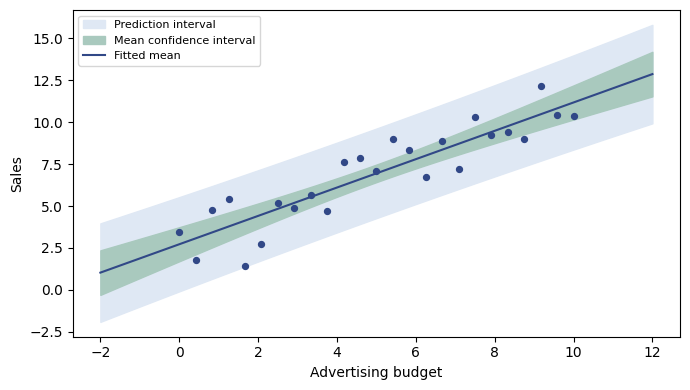

In [35]:
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display
image_dir = Path("图片")
image_dir.mkdir(exist_ok=True)
rng = np.random.default_rng(42)
x_plot = np.linspace(0., 10., 25)
y_plot = 3 + 0.8 * x_plot + rng.normal(0, 1.5, size=25)
Xp = np.column_stack((np.ones(25), x_plot))
bp = np.linalg.lstsq(Xp, y_plot, rcond=None)[0]
sp = np.sqrt(np.sum((y_plot - Xp @ bp) ** 2) / 23)
grid = np.linspace(-2., 12., 100)
Zp = np.column_stack((np.ones(100), grid))
Cp = np.linalg.solve(Xp.T @ Xp, np.eye(2))
hp = np.sum((Zp @ Cp) * Zp, axis=1)
center = Zp @ bp
cp = t.ppf(0.975, df=23)
fig, ax = plt.subplots(figsize=(7, 4))
ax.fill_between(grid, center-cp*sp*np.sqrt(1+hp), center+cp*sp*np.sqrt(1+hp), color="#DFE8F4", label="Prediction interval")
ax.fill_between(grid, center-cp*sp*np.sqrt(hp), center+cp*sp*np.sqrt(hp), color="#A9C9BE", label="Mean confidence interval")
ax.plot(grid, center, color="#314887", label="Fitted mean")
ax.scatter(x_plot, y_plot, s=18, color="#314887")
ax.set(xlabel="Advertising budget", ylabel="Sales")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(image_dir / "322-intervals.pdf")
fig.savefig(image_dir / "322-intervals.png", dpi=180)
display(fig)
plt.close(fig)


**逐步读代码**

- `Path` 表示目录，`mkdir(exist_ok=True)` 是路径对象的方法，目录存在时不报错。图片相对于 Notebook 的运行目录保存。

- `default_rng(42)` 创建固定种子的随机数生成器；`normal(0, 1.5, size=25)` 生成 25 个均值 0、标准差 1.5 的噪声；这些是模拟数据。`linspace` 在端点间均匀取点。

- 训练矩阵 Xp 有 25 行、2 列，残差自由度为 23；网格矩阵 Zp 有 100 行。`(Zp @ Cp) * Zp` 是对应元素相乘，`sum(axis=1)` 沿每行求和，等于每个新位置各自的二次型。

- `subplots` 返回画布 fig 和坐标轴 ax；`fill_between` 在上下界之间填色。先画更宽的预测区间，再画均值区间。颜色是可替换的十六进制样式值，不需背诵。

- `plot` 画均值曲线，`scatter` 画观测点；`set` 设置轴名，`legend` 显示图例，`tight_layout` 调整边距。

- 路径中的 `/` 用于拼接文件名；`savefig` 保存 PDF 矢量图与 PNG 预览，`dpi` 控制 PNG 分辨率。`display(fig)` 在 Notebook 输出图像，随后 `close` 释放画布，避免重复显示。

<a id="ref-fig-prediction-bands"></a>

![虚构单变量数据：同一位置的个体预测区间比均值置信区间更宽。](图片/322-intervals.png)

虚构单变量数据：同一位置的个体预测区间比均值置信区间更宽。

图~[3.2](#ref-fig-prediction-bands)由[代码 3.2.2-08](#ref-code-322-08)实际生成，公式来自[式（3.141）](#ref-eq-prediction-intervals)。图中固定随机种子只为复现教学例子，不代表真实广告实验。

**本节小结**

本节从[式（3.113）](#ref-eq-coef-cov)到[式（3.120）](#ref-eq-projection-chi)建立分布依据，再得到[式（3.123）](#ref-eq-multi-t)、[式（3.130）](#ref-eq-partial-f)和[式（3.141）](#ref-eq-prediction-intervals)。计算出来的 p 值与区间不自动验证模型假设。接下来把类别变量、交互和曲线纳入模型，并诊断假设可能失效的位置。

{

本小节练习与参考答案}

### 练习 3.43　协方差与标准误

$\sigma^2=4$，$C$ 的三个对角元为 $0.25,1,4$，求系数方差与理论标准误。推导无偏性需要正态误差吗？

**参考答案**

由[式（3.114）](#ref-eq-coef-se)，方差为 $1,4,16$，标准误为 $1,2,4$。无偏性只需零条件均值；协方差的简式还需同方差不相关，正态性用于后面的精确分布。

### 练习 3.44　残差自由度与新增变量

$n=20,p=3,RSS=32$，求残差自由度、$s^2,s$。若新增一个变量后 RSS 降为 31，RSE 一定下降吗？

**参考答案**

自由度 16，$s^2=2,s=\sqrt2$。新模型自由度 15，$s^2=31/15>2$，RSE 反而增大。RSS 需要降到 30 以下，新的噪声方差估计才小于原值。

### 练习 3.45　多元系数的双侧检验

$n=20,p=3,\widehat\beta_j=-0.6$，标准误 0.2，临界值近似 2.12，求统计量、结论与区间。没有正态性时，无偏性与精确 t 分布分别如何？

**参考答案**

$t=-3$，绝对值 3 大于 2.12，拒绝；区间 $[-1.024,-0.176]$。零条件均值仍可保证无偏，但不保证有限样本精确 t 分布。

### 练习 3.46　投影自由度与整体 F

$n=30,p=2,RSS_0=120,RSS_F=60$，求两个自由度和整体 F。整体拒绝能否推出所有系数非零，或指出具体哪个非零？

**参考答案**

分子自由度 2，分母 27；$F=((120-60)/2)/(60/27)=27/2=13.5$，不是 $27/4$。拒绝只支持至少一个斜率非零，不能推出全部，也不能确定哪一个。

### 练习 3.47　跳过的 F 分布代码练习

写出 $F_{\mathrm{obs}}=13.5$、自由度 $(2,27)$ 的右尾 p 值代码，是否乘以 2？若 p 值为 0.03、预设 $\alpha=0.01$，是否拒绝？临界值的 `ppf` 首参数是多少？

**参考答案**

使用 `f.sf(13.5, dfn=2, dfd=27)`，不乘以 2。$0.03>0.01$，不拒绝；右尾临界值用 `f.ppf(0.99, dfn=2, dfd=27)`，不是 0.995。

### 练习 3.48　F 与 t 的对应

简单回归中 $t=-2.5$，整体 F 为多少？能否从 F 看斜率符号？三个预测变量时整体检验拒绝，是否保证第一个变量的 t 检验也拒绝？

**参考答案**

由[式（3.129）](#ref-eq-f-t-square)，$F=6.25$，平方不保留符号。多元整体检验与单个检验的零假设不同，不保证第一个检验拒绝，甚至不保证在相同水平下至少一个单独 t 检验拒绝。

### 练习 3.49　部分 F 的两个计数对象

$n=30$、完整模型 $p=4$，联合检验两个系数为零，$RSS_R=70,RSS_F=50$，求自由度与 F。三个广告变量中检验广播和报纸时，简化模型保留什么？

**参考答案**

分子 2、分母 $30-4-1=25$；$F=(20/2)/(50/25)=5$。不能把分母写成 $30-2-1=27$。简化模型保留截距和电视，且重新拟合它们。

### 练习 3.50　跳过的部分 F 代码练习

完整广告输入按电视、广播、报纸排列，共 10 行。仅检验报纸系数为零，怎样选择简化输入？两个自由度是多少？把完整模型报纸系数清零、其余固定是否可行？

**参考答案**

使用 `X_reduced = X_full[:, [0, 1]]`。分子为 1，分母 $10-3-1=6$。必须重新拟合简化模型；固定其余系数通常没有得到简化模型的最小 RSS。见[代码 3.2.2-05](#ref-code-322-05)。

### 练习 3.51　调整指标与显著性

新增变量后训练 $R^2$ 从 0.70 增到 0.71，调整后指标一定增大吗？若部分 F 为 1.4，调整指标如何变化，是否保证 5% 显著？

**参考答案**

不一定，因为残差自由度也减少。满足[式（3.132）](#ref-eq-adjusted-f)的条件时，$F=1.4>1$ 说明调整指标上升；5% 显著还须比较对应 F 分布的 0.95 分位数，或判断右尾 p 值是否小于 0.05。

### 练习 3.52　前向选择的候选与停止

5 个预测变量已选入 2 个，下一轮分别加入一个变量，要尝试几个候选？RSS 从 40 降到 39，是否一定继续保留新增变量？

**参考答案**

剩余 3 个，尝试 3 个候选，每次重新拟合。不能仅因训练 RSS 下降而继续，需要预先确定的停止或评价准则；预测目标可使用验证误差。搜索方法与评价准则是两个问题。

### 练习 3.53　预测对象与方差分解

估计同预算下总体平均销量应使用什么区间，预测一个新市场用什么区间？若平均响应估计方差为 1，新噪声方差为 9，预测误差方差与标准差是多少？平均估计方差趋零后剩多少？

**参考答案**

分别为均值置信区间与个体预测区间。由[式（3.136）](#ref-eq-prediction-variance)，预测误差方差为 10、标准差 $\sqrt{10}$；平均估计方差趋零后，预测误差方差趋向 9。

### 练习 3.54　两种区间的完整计算

$\widehat\mu_0=20,s=3,h_0=1/9$，取临界值 $c=2$。计算两种区间。当 $h_0\to0,s\to\sigma>0$，预测标准误趋向什么？

**参考答案**

均值标准误 $3\sqrt{1/9}=1$，区间 $[18,22]$。预测标准误 $3\sqrt{10/9}=\sqrt{10}$，区间 $[20-2\sqrt{10},20+2\sqrt{10}]\approx[13.68,26.32]$。预测标准误趋向 $\sigma$，均值标准误趋向零。

### 练习 3.55　输入位置与外推

$n=20,\bar x=10,S_{xx}=200$，求 $x_0=10,20$ 处的 $h_0$。若训练预算在 20 到 80，给预算 200 计算区间就能保证业务可靠性吗？

**参考答案**

由[式（3.143）](#ref-eq-simple-h)，分别为 0.05 与 $0.05+100/200=0.55$，后者均值区间更宽。不能保证外推可靠，因为原均值关系可能在新范围失效，区间不会自动覆盖模型偏差。

## 回归模型中的其他考虑（Other Considerations in the Regression Model）

## 定性预测变量（Qualitative Predictors）

<a id="ref-sec-331"></a>

> 整理依据：手稿第 11 页要求从二类别扩展到多类别，并说明为何不能随意用 1、2、3 编码；正文按已学讲解整理。

**本节目标**

预测变量可以是类别，响应仍是销量或销售额，因此任务仍是回归。使用指示变量，把类别差异写进条件均值，并明确基准类别与系数解释。

<a id="ref-topic-binary-category"></a>

### 思考40　两种门店怎样进入回归模型？

社区店月销售额为 $8,10,12$ 万元，商场店为 $12,14,16$ 万元。定义 $D=0$ 表示社区店、$D=1$ 表示商场店，建立

<a id="ref-eq-binary-category"></a>

$$
Y=\beta_0+\beta_1D+\varepsilon,\quad E[\varepsilon\mid D]=0,
\quad E[Y\mid D=0]=\beta_0,\quad E[Y\mid D=1]=\beta_0+\beta_1.
\tag{3.144}
$$

社区店是基准类别；截距是其总体均值，$\beta_1$ 是商场店减去社区店的总体均值差。0 和 1 只是类别标识，不是类别具有天然的数量大小关系。

令 $\mathcal I_0,\mathcal I_1$ 是两组样本下标。只有类别变量和截距时，目标为

<a id="ref-eq-group-rss"></a>

$$
RSS(b_0,b_1)=\sum_{i\in\mathcal I_0}(y_i-b_0)^2
+\sum_{i\in\mathcal I_1}(y_i-b_0-b_1)^2.
\tag{3.145}
$$

换元 $m_0=b_0,m_1=b_0+b_1$，可反解 $b_0=m_0,b_1=m_1-m_0$，因此没有限制原来的参数集合。目标变成两组各自围绕 $m_g$ 的平方和。对 $m_g$ 求导：$-2\sum_{i\in\mathcal I_g}(y_i-m_g)=0$，若组内样本数 $n_g>0$，则 $m_g=\bar y_g$，且二阶导数 $2n_g>0$。于是

<a id="ref-eq-group-estimates"></a>

$$
\widehat\beta_0=\bar y_0,\qquad
\widehat\beta_1=\bar y_1-\bar y_0.
\tag{3.146}
$$

本例是 $\widehat Y=10+4D$；如果交换编码，变成 $\widehat Y=14-4D'$，每个门店的预测、残差和 RSS 都不变。加入其他预测变量后，类别系数通常不再等于原始两组样本均值之差，而是对应其他输入固定时的模型差异。

<a id="ref-topic-multi-category"></a>

### 思考41　三种及更多类别如何处理？

再增加街边店，选择社区店为基准，用 $D_M,D_S$ 表示商场和街边：

| 类别 | $D_M$ | $D_S$ |
|---|---:|---:|
|社区店|0|0|
|商场店|1|0|
|街边店|0|1|

<a id="ref-eq-three-categories"></a>

$$
Y=\beta_0+\beta_1D_M+\beta_2D_S+\varepsilon.
\tag{3.147}
$$

三组条件均值分别是 $\beta_0,\beta_0+\beta_1,\beta_0+\beta_2$。若样本均值为 $10,14,12$，拟合式为 $10+4D_M+2D_S$。商场与街边的差是 $4-2=2$，系数 4 表示商场相对社区的差。

完整独热编码（one-hot encoding）为每个类别设置一列，每行恰好一个 1。含截距时通常删除一个基准列，得到 $K-1$ 个虚拟变量。原因是若保留全部 $K$ 列，有

<a id="ref-eq-dummy-trap"></a>

$$
D_1+\cdots+D_K=\mathbf1.
\tag{3.148}
$$

截距列等于类别列之和，出现[式（3.105）](#ref-eq-collinear-combination)同类的完全共线性；截距增加 $c$、所有类别系数减去 $c$，预测不变。也可不设截距、保留全部类别列，此时只有类别变量的模型中每个系数直接对应组均值。

<a id="ref-topic-category-numbers"></a>

### 思考42　为什么不能随意把三个无序类别编码为 1、2、3？

若把类别编号当作一个数值预测变量，模型强制三个均值为 $\beta_0+\beta_1,\beta_0+2\beta_1,\beta_0+3\beta_1$，从而要求

<a id="ref-eq-category-equal-gap"></a>

$$
\mu_2-\mu_1=\mu_3-\mu_2=\beta_1.
\tag{3.149}
$$

无序类别不提供这种等间距信息。低、中、高虽有自然顺序，直接按 1、2、3 放进线性模型也引入相邻影响相同的额外假设，仍须判断是否合理。

**类别整体检验与因果解释**

对[式（3.147）](#ref-eq-three-categories)，$H_0:\beta_1=\beta_2=0$ 等价于三组条件均值相同，可用[式（3.130）](#ref-eq-partial-f)。若还有面积等变量，简化模型保留其他变量，只移除整组类别指示列。观测中的组均值差不自动表示改变门店类型的因果效果。

## Python：编码、拟合与换基准核对

<a id="ref-code-331-01"></a>

### 代码 3.3.1-01　用布尔比较构造类别指示列

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/331-01.html)

In [36]:
groups = np.array(["community"] * 3 + ["mall"] * 3 + ["street"] * 3)
y_group = np.array([8.,10.,12.,12.,14.,16.,10.,12.,14.])
d_mall = (groups == "mall").astype(float)
d_street = (groups == "street").astype(float)
X_group = np.column_stack((d_mall, d_street))
print("encoded shape:", X_group.shape)
print(X_group)


encoded shape: (9, 2)
[[0. 0.]
 [0. 0.]
 [0. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [0. 1.]
 [0. 1.]
 [0. 1.]]


**逐步读代码**

- 列表乘 3 表示重复三次，两个列表用加号连接；groups 和 y\_group 的行顺序必须一致。

- `groups == "mall"` 对每个元素比较并返回布尔数组，`astype(float)` 把 True、False 转成 1.0、0.0。

- 只建立商场和街边两列，社区两列都为零，是基准；模型下一块会自动拟合截距。

<a id="ref-code-331-02"></a>

### 代码 3.3.1-02　拟合组均值并检查完整独热的秩

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/331-02.html)

In [37]:
group_model = LinearRegression().fit(X_group, y_group)
group_predictions = group_model.predict(np.array([[0.,0.], [1.,0.], [0.,1.]]))
d_community = (groups == "community").astype(float)
all_dummies = np.column_stack((d_community, d_mall, d_street))
X_redundant = np.column_stack((np.ones(len(groups)), all_dummies))
assert np.allclose(all_dummies.sum(axis=1), 1.0)
print("intercept, coefficients:", group_model.intercept_, group_model.coef_)
print("group predictions:", group_predictions)
print("columns, rank with all dummies:", X_redundant.shape[1], np.linalg.matrix_rank(X_redundant))


intercept, coefficients: 10.000000000000002 [4. 2.]
group predictions: [10. 14. 12.]
columns, rank with all dummies: 4 3


**逐步读代码**

- 三个待预测行依次对应社区、商场、街边，顺序由我们明确指定。

- 完整独热编码每行和为 1，所以与截距列重复；`matrix_rank` 计算数值秩。4 列只有秩 3，说明全类别列加截距不能唯一识别系数。

- 这个断言检查编码规则；它不表示真实数据没有其他质量问题。

<a id="ref-code-331-03"></a>

### 代码 3.3.1-03　更换基准类别并核对预测不变

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/331-03.html)

In [38]:
X_group_new = np.column_stack((d_community, d_street))
group_model_new = LinearRegression().fit(X_group_new, y_group)
assert np.allclose(group_model.predict(X_group), group_model_new.predict(X_group_new))
print("new baseline: mall")
print("intercept:", round(group_model_new.intercept_, 6))
print("community, street coefficients:", np.round(group_model_new.coef_, 6))


new baseline: mall
intercept: 14.0
community, street coefficients: [-4. -2.]


**逐步读代码**

- 现在省略商场列，商场成为基准；两列分别表示社区、街边相对商场的差。

- 两种编码对应同一个均值模型空间，重新拟合后逐行预测应相同；`allclose` 检查该结论在本例中成立。系数改变不意味着门店预测改变。

{

本小节练习与参考答案}

### 练习 3.56　会员编码与更换基准

$D=0$ 为非会员、$D=1$ 为会员，拟合 $\widehat Y=80+25D$。解释两组预测和系数；若会员改为 0、非会员改为 1，新系数是多少？

**参考答案**

非会员 80、会员 105，25 是会员减去非会员的模型均值差。换编码后为 $\widehat Y=105-25D^{\mathrm{new}}$，每个人的预测不变。

### 练习 3.57　多类别与类别对比

地区有东南西北四类，含截距、东部为基准，需要几个指示变量？东部编码是什么？另有 $\widehat Y=10+4D_M+2D_S$，商场与街边预测相差多少？

**参考答案**

需要 3 个指示变量，东部为 $(0,0,0)$。商场为 14、街边为 12，相差 2；系数 4 是商场相对基准社区的差，不能直接用来表示商场减街边。

### 练习 3.58　独热编码与完全共线性

为何含截距时通常删除一个独热列？无序类别直接编码 1、2、3 并作线性回归，增加了什么假设？

**参考答案**

所有完整独热列之和等于截距列，造成线性依赖，见[式（3.148）](#ref-eq-dummy-trap)。直接数值编码使相邻类别预测均值差都等于同一个斜率，强制等间距及顺序假设。

## 线性模型的扩展（Extensions of the Linear Model）

<a id="ref-sec-332"></a>

> 整理依据：手稿第 11 页要求补入已学交互作用、多项式和逐步推导。

**本节目标**

一个变量的关系可能随另一个变量改变，或者平均关系本身呈曲线。通过构造特征扩大模型表达能力，同时保持模型对参数线性。

<a id="ref-topic-interaction"></a>

### 思考43　电视预算的关系会不会随着广播预算变化？

可加模型 $f(T,R)=\beta_0+\beta_1T+\beta_2R$ 中，固定广播 $R$，电视增加 $\Delta T$，预测变化恒为 $\beta_1\Delta T$，与 $R$ 无关。若两个渠道共同出现时有不同的关联，需要乘积特征：

<a id="ref-eq-interaction-model"></a>

$$
f(T,R)=\beta_0+\beta_1T+\beta_2R+\beta_3TR
=\beta_0+\beta_2R+(\beta_1+\beta_3R)T.
\tag{3.150}
$$

逐项相减得

<a id="ref-eq-interaction-change"></a>

$$
\begin{aligned}
f(T+\Delta T,R)-f(T,R)
&=\beta_1\Delta T+\beta_3[(T+\Delta T)R-TR]\\
&=(\beta_1+\beta_3R)\Delta T,\\
\frac{\partial f}{\partial T}&=\beta_1+\beta_3R,\qquad
\frac{\partial f}{\partial R}=\beta_2+\beta_3T,\qquad
\frac{\partial^2f}{\partial T\partial R}=\beta_3.
\end{aligned}
\tag{3.151}
$$

示例 $\widehat f=5+0.04T+0.10R+0.002TR$ 中，把电视增加 10，在广播为 0、20、50 时，预测增量分别为 0.4、0.8、1.4 千件。正交互系数表示模型中斜率随另一变量增大，负交互系数表示斜率减小，但斜率不一定已变负。

**交互项改变主项的解释**

$\beta_1$ 是 $R=0$ 时电视的斜率，$\beta_2$ 是 $T=0$ 时广播的斜率；不再是所有位置共有的关系。包含 $TR$ 时通常也保留 $T,R$，称为层级原则，不能仅因某一主项 p 值较大就机械删除。统计交互不自动证明两个渠道的因果协同。

设置 $z_1=T,z_2=R,z_3=TR$ 后，模型仍是 $Y=\beta_0+\beta_1z_1+\beta_2z_2+\beta_3z_3+\varepsilon$。设计矩阵每行是 $(1,T_i,R_i,T_iR_i)$，待估系数没有相乘或取非线性函数，因此仍是线性回归。可按[式（3.102）](#ref-eq-normal-equations)估计，并在条件成立时检验 $\beta_3=0$。

<a id="ref-topic-polynomial"></a>

### 思考44　预算的边际关联随自身水平变化怎么办？

若广告增长逐渐饱和，可尝试二次模型：

<a id="ref-eq-quadratic"></a>

$$
f(T)=\beta_0+\beta_1T+\beta_2T^2,
\quad f'(T)=\beta_1+2\beta_2T,\quad f''(T)=2\beta_2.
\tag{3.152}
$$

$\beta_2<0$ 时斜率随预算下降，但只有一阶导数为负时预测销量才下降。用假设模型 $\widehat f(T)=5+0.2T-0.001T^2$，有限预算变化不能总用导数乘增量代替：

<a id="ref-eq-quadratic-change"></a>

$$
\begin{aligned}
\widehat f(T+\Delta T)-\widehat f(T)
&=0.2\Delta T-0.001[(T+\Delta T)^2-T^2]\\
&=(0.2-0.002T)\Delta T-0.001(\Delta T)^2.
\end{aligned}
\tag{3.153}
$$

从 20 增加到 30 的精确增量为 1.5 千件；起点导数乘以 10 得到 1.6，只是一阶近似。交互模型固定另一变量后为一次函数，[式（3.151）](#ref-eq-interaction-change)则是精确增量。

二次模型的设计矩阵为 $X=(\mathbf1,\mathbf T,\mathbf T^2)$，仍对系数线性。$T^2$ 是 $T$ 的函数不代表这几列必然线性相关：如果至少有三个不同的预算值，非零二次多项式不能在三个位置同时为零，因此这三列线性无关。但线性无关不保证条件数良好，大数值或窄范围下的幂次特征仍可能数值不稳定。

<a id="ref-topic-polynomial-check"></a>

### 思考45　怎样决定保留平方项或更高次项？

直线模型嵌套于二次模型，$H_0:\beta_2=0$ 可用 t 检验或单约束部分 F 检验；由[式（3.129）](#ref-eq-f-t-square)对应的单约束关系，两者等价。若增加二次和三次项，要联合检验两个系数，用[式（3.130）](#ref-eq-partial-f)。

**曲线更灵活，也更需要检查泛化与外推**

高次多项式可降低训练误差，也可能拟合噪声、增大方差与数值不稳定。[式（3.153）](#ref-eq-quadratic-change)所用模型在很大预算下会预测负销量，说明局部合理不等于全范围合理。保留高次项应结合验证表现、残差结构及业务常识；一次显著检验不能替代这些判断。

## Python：把乘积与平方变成输入列

<a id="ref-code-332-01"></a>

### 代码 3.3.2-01　构造交互项并检查有限增量

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/332-01.html)

In [39]:
T = np.array([50., 50.])
R = np.array([0., 20.])
X_interaction = np.column_stack((np.ones(2), T, R, T * R))
b_interaction = np.array([5., 0.04, 0.10, 0.002])
interaction_predictions = X_interaction @ b_interaction
increase = (b_interaction[1] + b_interaction[3] * R) * 10
print("predictions:", interaction_predictions)
print("increase for TV +10:", increase)


predictions: [ 7. 11.]
increase for TV +10: [0.4 0.8]


**逐步读代码**

- `T * R` 对应行相乘生成乘积特征。系数顺序必须和列顺序一致：截距、电视、广播、交互。

- 本块使用指定的假设系数，没有从这两个样本拟合四个参数。`b_interaction[1]` 和 `[3]` 分别取电视主项和交互系数。

- 增加 10 的公式固定广播预算，因此结果按每一行的广播水平分别计算。

<a id="ref-code-332-02"></a>

### 代码 3.3.2-02　比较直线与二次曲线

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/332-02.html)

In [40]:
x_curve = np.arange(5, dtype=float)
y_curve = 2 + x_curve ** 2
X_line = np.column_stack((np.ones(5), x_curve))
X_quad = np.column_stack((np.ones(5), x_curve, x_curve ** 2))
b_line = np.linalg.lstsq(X_line, y_curve, rcond=None)[0]
b_quad = np.linalg.lstsq(X_quad, y_curve, rcond=None)[0]
e_line = y_curve - X_line @ b_line
e_quad = y_curve - X_quad @ b_quad
print("line coefficients:", np.round(b_line, 6))
print("quadratic coefficients:", np.round(b_quad, 6))
print("line residuals:", np.round(e_line, 6))
print("quadratic RSS:", round(np.sum(e_quad ** 2), 6))


line coefficients: [-0.  4.]
quadratic coefficients: [2. 0. 1.]
line residuals: [ 2. -1. -2. -1.  2.]
quadratic RSS: 0.0


**逐步读代码**

- `arange(5, dtype=float)` 生成浮点数 0 到 4；y\_curve 按已知二次关系构造，不含噪声。

- 两个设计矩阵分别为 5 行 2 列、5 行 3 列。平方特征增加表达能力，参数依然通过普通最小二乘求解。

- 二次 RSS 近似零只是因为这份模拟数据恰好来自该曲线；真实数据含噪声时不应期待全部残差为零。

{

本小节练习与参考答案}

### 练习 3.59　交互项练习与参考答案

$\widehat Y=5+0.02T+0.10R+0.001TR$。固定 $R=30$，电视预算增加 10，销量增加多少？能否直接用 $0.02\times10$？为什么它仍是线性回归？

**参考答案**

由[式（3.151）](#ref-eq-interaction-change)，增量 $(0.02+0.001\times30)\times10=0.5$，不能忽略交互项。模型对待估参数线性；构造输入特征 $T,R,TR$ 后仍是 $X\boldsymbol\beta$。

### 练习 3.60　导数与有限增量

$\widehat f(x)=2+3x-0.5x^2$。求 $x=1$ 处斜率及从 1 增加到 2 的精确预测增量。

**参考答案**

$\widehat f^{\prime}(x)=3-x$，起点斜率为 2。$\widehat f(1)=4.5,\widehat f(2)=6$，精确增量为 1.5。导数乘以增量为 2，只是一阶近似，还要加二次项 $-0.5(\Delta x)^2$。

### 练习 3.61　联合检验高次项

从截距加 $x$ 的模型扩展到截距加 $x,x^2,x^3$，检验新增两项是否提供解释能力，原假设与自由度是什么？假设列满秩且 $n>4$。

**参考答案**

$H_0:\beta_2=\beta_3=0$，分子自由度 2，完整模型共四个参数，分母为 $n-4$。$F=((RSS_R-RSS_F)/2)/(RSS_F/(n-4))$。

## 潜在问题（Potential Problems）

<a id="ref-sec-333"></a>

> 整理依据：手稿第 11 页要求按已学六类问题给出例子、推导、分析与处理方向；共线性连接第 5 页及前面保留的 MP 逆、条件数专题。

**本节目标**

拟合之后检查：均值形式是否正确，噪声是否相关，方差是否恒定，是否有异常响应或特殊输入，特征信息是否冗余。每种诊断都需要结合业务；不能把一个图形或一个阈值当作自动删除数据的命令。

<a id="ref-topic-nonlinearity"></a>

### 思考46　非线性：残差还留下了什么规律？

残差 $e_i=y_i-\widehat y_i$ 为正表示低估，为负表示高估。常画残差对某个输入或拟合值，检查局部残差中心是否随位置改变。高 $R^2$ 或斜率显著不保证均值形式正确。

虚构配送数据不加噪声，只为分离模型失配。输入依次为 $0,1,2,3,4$，响应满足 $y=2+x^2$，依次为 $2,3,6,11,18$。$\bar x=2,\bar y=8,S_{xx}=10,S_{xy}=40$，由[式（3.15）](#ref-eq-prior-sections-3-1-1-011)得到直线 $\widehat y=4x$。残差为

<a id="ref-eq-u-residual"></a>

$$
\mathbf e=(2,-1,-2,-1,2)^\mathsf T,\qquad \sum_i e_i=0.
\tag{3.154}
$$

两端低估、中间高估，残差图呈 U 形。残差和为零是含截距 OLS 的代数性质，不能证明没有遗漏关系。由[式（3.102）](#ref-eq-normal-equations)，残差只保证与已进入模型的列正交，不保证与未进入的平方项正交。

真实均值向量记为 $\boldsymbol\mu$，即使它不在 $X$ 的列空间，也可以利用[式（3.115）](#ref-eq-hat-residual)写成

<a id="ref-eq-residual-misspec"></a>

$$
\mathbf e=(I-H)(\boldsymbol\mu+\boldsymbol\varepsilon)
=(I-H)\boldsymbol\mu+(I-H)\boldsymbol\varepsilon.
\tag{3.155}
$$

第一项是当前模型无法表示的平均规律，第二项是拟合后留下的噪声。模型正确时第一项为零。因此残差不是直接等于真实误差。明显弯曲可提示加入平方项、变换或检查遗漏变量，但有限样本偶然性也可能产生形状；改进后还应检查验证误差和业务合理性。

<a id="ref-topic-correlated-errors"></a>

### 思考47　误差相关：连续观测不一定提供独立信息

连续日期的销量可能同时受持续热点或天气影响，模型控制预算后仍连续高估或低估。相关性表现为 $\operatorname{Cov}(\varepsilon_i,\varepsilon_j)\ne0$；按时间排序本身不意味着相关，遗漏趋势也可能产生类似现象。

两次观测 $Y_i=\mu+\varepsilon_i$，误差均值零、方差 $\sigma^2$、协方差 $\rho\sigma^2$。样本均值的方差为

<a id="ref-eq-correlated-mean"></a>

$$
\operatorname{Var}\left(\frac{Y_1+Y_2}{2}\right)
=\frac14(\sigma^2+\sigma^2+2\rho\sigma^2)
=\frac{\sigma^2}{2}(1+\rho).
\tag{3.156}
$$

$\rho=0.8$ 时为 $0.9\sigma^2$，远大于错误假设独立得到的 $0.5\sigma^2$。一起偏高偏低的误差不能充分相互抵消。对一般回归，每个系数标准误如何改变还依赖设计矩阵，不能断言正相关一定低估所有系数的标准误。

若 $E[\boldsymbol\varepsilon\mid X]=0$，[式（3.112）](#ref-eq-coef-unbiased)仍成立；但协方差矩阵改为一般 $\Omega$ 时，[式（3.113）](#ref-eq-coef-cov)应改为

<a id="ref-eq-general-cov"></a>

$$
\operatorname{Cov}(\widehat{\boldsymbol\beta}\mid X)
=A\Omega A^\mathsf T
=(X^\mathsf TX)^{-1}X^\mathsf T\Omega X(X^\mathsf TX)^{-1}.
\tag{3.157}
$$

在 $\Omega=\sigma^2I$ 下可得到旧公式。可以画残差对时间、$e_t$ 对 $e_{t-1}$ 观察连续结构；图形只是线索，拟合也给残差引入约束。先检查遗漏趋势、季节和节假日，再考虑相关误差模型或适用的稳健推断。预测未来时验证划分应尊重时间顺序，避免使用未来信息。

<a id="ref-topic-heteroskedasticity"></a>

### 思考48　异方差：不同位置的噪声大小可能不同

小门店平均销量 10 万元、标准差 1 万元；大门店平均 100 万元、标准差 10 万元。相对波动相似，绝对波动却不同。异方差允许

<a id="ref-eq-heteroskedasticity"></a>

$$
E[\varepsilon\mid X=x]=0,\qquad
\operatorname{Var}(\varepsilon\mid X=x)=\sigma^2(x).
\tag{3.158}
$$

残差中心随输入弯曲主要提示均值失配；中心约在零附近但宽度持续扩大，主要提示异方差，二者可能同时存在。即使真实误差同方差，原始残差也有 $\operatorname{Var}(e_i\mid X)=\sigma^2(1-h_{ii})$，所以不能把任何轻微宽度差都判为异方差。

误差不相关但异方差时，$\Omega=\operatorname{diag}(\sigma_1^2,\ldots,\sigma_n^2)$，仍用[式（3.157）](#ref-eq-general-cov)。零条件均值保证 OLS 无偏，但同方差标准误及精确 t/F 分布不能直接沿用。新观测独立于训练样本时，[式（3.136）](#ref-eq-prediction-variance)推广为

<a id="ref-eq-hetero-prediction"></a>

$$
\operatorname{Var}(Y_{\mathrm{new}}-\widehat f(x_0))
=\operatorname{Var}(\widehat f(x_0))+\sigma^2(x_0).
\tag{3.159}
$$

均值方差相同的位置也会因个体噪声不同而需要不同宽度的预测区间。

**处理方向及边界**

正响应且波动随规模增长时，可考虑 $\log Y$ 等变换，但不保证消除异方差，且 $\exp(E[\log Y\mid X])$ 一般不等于 $E[Y\mid X]$。若噪声方差已知或可合理估计，可考虑最小化 $\sum_i w_i(y_i-\widehat y_i)^2$，常取 $w_i\propto1/\sigma_i^2$。也可在适当条件下使用异方差稳健标准误；它不自动修复均值模型，也不自动提供局部个体噪声。上述是处理方向，本节不新增完整方法专题。

<a id="ref-topic-outlier-leverage"></a>

### 思考49　异常点、高杠杆点和强影响点有何不同？

异常点是给定输入后响应明显偏离模型的观测。若多数配送样本在 $x=1$ 到 5，趋势为 $y\approx2+3x$，点 $(3,30)$ 相对于约 11 的典型时间明显偏高。响应大本身不等于异常，长距离本来可能耗时长。

点 $(20,62)$ 的输入位置很特殊，是高杠杆的候选，却与原趋势一致，不一定明显改变拟合。高杠杆看输入，只依赖 $X$；强影响点看删除或改变该观测是否明显改变系数或拟合，需要结合 $y$。

由[式（3.115）](#ref-eq-hat-residual)展开第 $i$ 个拟合值：

<a id="ref-eq-leverage"></a>

$$
\widehat y_i=\sum_jh_{ij}y_j,\qquad
h_{ii}=\mathbf z_i^\mathsf T(X^\mathsf TX)^{-1}\mathbf z_i,
\qquad\sum_i h_{ii}=p+1.
\tag{3.160}
$$

固定 $X$ 只改变 $y_i$ 一个增量，自己的拟合值改变 $h_{ii}$ 倍增量，其他拟合值也可能改变。迹恒等式已在[式（3.117）](#ref-eq-expected-rss)证明，因此平均杠杆值为 $(p+1)/n$。对标准坐标向量 $\mathbf a_i$，$h_{ii}=\mathbf a_i^\mathsf TH\mathbf a_i=\|H\mathbf a_i\|^2\in[0,1]$，因为正交投影不增长度。该范围针对训练点，不能套到任意新输入的 $h_0$。简单回归时由[式（3.143）](#ref-eq-simple-h)把 $x_0$ 换成 $x_i$ 即得杠杆值。

高杠杆点可能把拟合直线拉向自身，因此最终残差很小也不排除强影响。可以比较全数据估计 $\widehat{\boldsymbol\beta}$ 与删除第 $i$ 点后重新拟合的 $\widehat{\boldsymbol\beta}_{(-i)}$。异常点、高杠杆、强影响不是同义词。

**发现特殊点后不能自动删除**

先检查单位、录入和测量；再判断是否属于未来要服务的业务人群。真实的特殊情景可能提示模型覆盖不足。应记录删除前后的敏感性，而非仅为了提高拟合分数移除难预测样本。

<a id="ref-topic-vif"></a>

### 思考50　共线性如何与系数方差连接？

完全与近似共线性的例子、MP 逆和条件数见思考~[23](#ref-topic-rank-deficient)至思考~[25](#ref-topic-condition-number)。这里补原书的方差膨胀因子（VIF）。两两相关不高也不能排除 $X_3\approx X_1+X_2$。对第 $j$ 个预测变量做辅助回归：用截距和所有其他预测变量解释它，得到 $R_j^2$。定义

<a id="ref-eq-vif-definition"></a>

$$
\operatorname{VIF}_j=\frac1{1-R_j^2}.
\tag{3.161}
$$

这是辅助回归的决定系数，不是主模型解释响应 $Y$ 的决定系数。

以下证明为何它膨胀方差。将主模型写成 $\mathbf y=W\boldsymbol\gamma+\mathbf x_j\beta_j+\boldsymbol\varepsilon$，其中 $W$ 含截距和其他预测变量。令 $M_W=I-W(W^\mathsf TW)^{-1}W^\mathsf T$、$\mathbf z=M_W\mathbf x_j$。固定候选系数 $b$，对其他系数最小二乘后，目标变成 $\|M_W\mathbf y-b\mathbf z\|^2$。对 $b$ 求导并令零：

<a id="ref-eq-fwl"></a>

$$
-2\mathbf z^\mathsf T(M_W\mathbf y-b\mathbf z)=0
\quad\Longrightarrow\quad
\widehat\beta_j=\frac{\mathbf z^\mathsf TM_W\mathbf y}{\mathbf z^\mathsf T\mathbf z}
=\frac{\mathbf z^\mathsf T\mathbf y}{\mathbf z^\mathsf T\mathbf z}.
\tag{3.162}
$$

最后一步用 $M_W\mathbf z=\mathbf z$ 及对称性。又因 $\mathbf z^\mathsf TW=0$、$\mathbf z^\mathsf T\mathbf x_j=\mathbf z^\mathsf T\mathbf z$，代入真实模型：

<a id="ref-eq-fwl-variance"></a>

$$
\widehat\beta_j=\beta_j+\frac{\mathbf z^\mathsf T\boldsymbol\varepsilon}{\mathbf z^\mathsf T\mathbf z},
\qquad\operatorname{Var}(\widehat\beta_j\mid X)
=\frac{\sigma^2\mathbf z^\mathsf T\mathbf z}{(\mathbf z^\mathsf T\mathbf z)^2}
=\frac{\sigma^2}{\mathbf z^\mathsf T\mathbf z}.
\tag{3.163}
$$

这里使用主模型正确、列满秩、零均值及 $\operatorname{Cov}(\boldsymbol\varepsilon)=\sigma^2I$。令 $S_{jj}=\sum_i(x_{ij}-\bar x_j)^2$，辅助回归含截距，因此 $\mathbf z^\mathsf T\mathbf z=S_{jj}(1-R_j^2)$。最终得到

<a id="ref-eq-vif-variance"></a>

$$
\operatorname{Var}(\widehat\beta_j\mid X)
=\frac{\sigma^2}{S_{jj}(1-R_j^2)}
=\frac{\sigma^2}{S_{jj}}\operatorname{VIF}_j.
\tag{3.164}
$$

其他变量解释掉的部分越多，留下用于单独识别该系数的变化就越少。VIF 为 10 表示在固定噪声方差和该变量自身离散程度的比较下，方差放大 10 倍，标准误放大 $\sqrt{10}$ 倍。$R_j^2=1$ 对应完全共线性，不满足此处有限方差公式的列满秩前提。

**VIF、条件数与处理选择**

5 或 10 是常见关注阈值，不是超过就必须删除的定理。VIF 逐个变量分析线性信息重叠，原始条件数看整个矩阵的伸缩差异；非零单位缩放不改变含截距辅助回归的 VIF，却可能改变原始条件数。可考虑收集更有区分度的数据、合理合并冗余特征、按业务选择变量；正则化留待第六章。预测目的与单独系数解释的要求也不同。

## Python：把六类诊断落到可检查的对象上

<a id="ref-code-333-01"></a>

### 代码 3.3.3-01　绘制直线失配与二次修正的残差图

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/333-01.html)

linear residual sum: 0.0


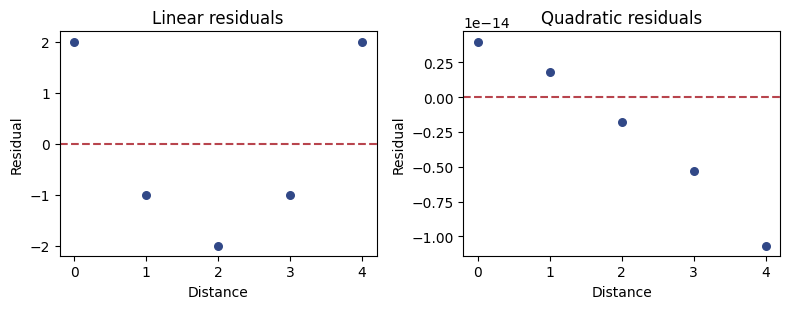

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
for ax, errors, title in zip(axes, [e_line, e_quad], ["Linear residuals", "Quadratic residuals"]):
    ax.scatter(x_curve, errors, color="#314887", s=30)
    ax.axhline(0, color="#B8444D", linestyle="--")
    ax.set(xlabel="Distance", ylabel="Residual", title=title)
fig.tight_layout()
fig.savefig(image_dir / "333-residuals.pdf")
fig.savefig(image_dir / "333-residuals.png", dpi=180)
print("linear residual sum:", round(np.sum(e_line), 6))
display(fig)
plt.close(fig)


**逐步读代码**

- 沿用代码 3.3.2-02 的配送数据。`subplots(1, 2)` 创建一行两个坐标轴。

- `zip` 将坐标轴、残差数组、标题按位置配对；循环变量 ax 每次指向一个子图。`axhline(0)` 画残差零线，虚线用于参考。

- 残差和近似零不能排除 U 形；两幅图分别展示遗漏曲线与正确表达曲线后的残差。保存和显示步骤与代码 3.2.2-08 相同。

<a id="ref-fig-residual-u"></a>

![虚构无噪声配送数据：直线残差呈 U 形，二次模型能表示真实均值。](图片/333-residuals.png)

虚构无噪声配送数据：直线残差呈 U 形，二次模型能表示真实均值。

<a id="ref-code-333-02"></a>

### 代码 3.3.3-02　模拟相关误差与异方差的图形线索

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/333-02.html)

simulated observations: 100 100


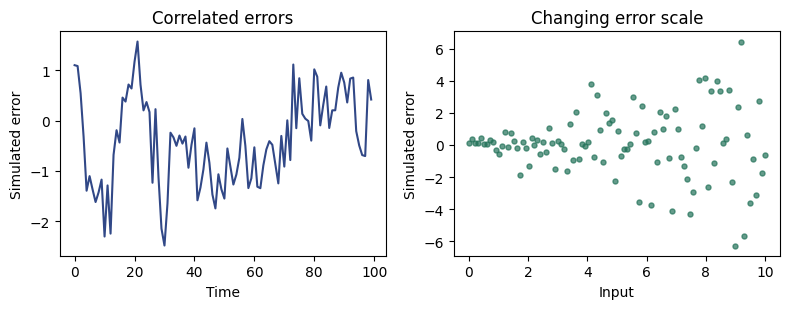

In [42]:
rng_noise = np.random.default_rng(17)
innovations = rng_noise.normal(size=100)
correlated = np.zeros(100)
correlated[0] = innovations[0]
for i in range(1, 100):
    correlated[i] = 0.8 * correlated[i-1] + 0.6 * innovations[i]
x_noise = np.linspace(0., 10., 100)
hetero = (0.2 + 0.3 * x_noise) * rng_noise.normal(size=100)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
axes[0].plot(correlated, color="#314887")
axes[0].set(xlabel="Time", ylabel="Simulated error", title="Correlated errors")
axes[1].scatter(x_noise, hetero, s=13, color="#24735A", alpha=0.7)
axes[1].set(xlabel="Input", ylabel="Simulated error", title="Changing error scale")
fig.tight_layout()
fig.savefig(image_dir / "333-noise.pdf")
fig.savefig(image_dir / "333-noise.png", dpi=180)
print("simulated observations:", len(correlated), len(hetero))
display(fig)
plt.close(fig)


**逐步读代码**

- `zeros(100)` 创建待填的数组，先给第一个值，再在 `range(1, 100)` 中依次计算索引 1 到 99。每个新误差包含前一个的 0.8 倍，故产生时间联系。

- 第二种噪声将独立标准正态数乘以随输入增大的尺度；均值仍为零，但条件方差变化。

- 这两幅图画的是我们构造的真实噪声，不是对某个模型拟合后的残差；不能把模拟机制当作从真实图形完成了统计检验。`alpha=0.7` 仅控制散点透明度。

<a id="ref-fig-noise-patterns"></a>

![模拟误差而非拟合残差：左为时间相关噪声，右为随输入扩大尺度的噪声。图形用于理解机制，不是自动检验。](图片/333-noise.png)

模拟误差而非拟合残差：左为时间相关噪声，右为随输入扩大尺度的噪声。图形用于理解机制，不是自动检验。

<a id="ref-code-333-03"></a>

### 代码 3.3.3-03　计算杠杆并检查删除观测后的变化

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/333-03.html)

In [43]:
x_influence = np.array([1., 2., 3., 4., 5., 20.])
y_influence = np.array([5., 8., 11., 14., 17., 40.])
Xi = np.column_stack((np.ones(6), x_influence))
bi = np.linalg.lstsq(Xi, y_influence, rcond=None)[0]
Hi = Xi @ np.linalg.pinv(Xi)
leverage = np.diag(Hi)
bi_without = np.linalg.lstsq(Xi[:-1], y_influence[:-1], rcond=None)[0]
print("leverage:", np.round(leverage, 6))
print("full coefficients:", np.round(bi, 6))
print("without last point:", np.round(bi_without, 6))
print("last residual:", round((y_influence - Xi @ bi)[-1], 6))


leverage: [0.259801 0.225249 0.198671 0.180066 0.169435 0.966777]
full coefficients: [5.581395 1.757475]
without last point: [2. 3.]
last residual: -0.730897


**逐步读代码**

- 前五点沿原关系分布，最后一点输入很远且偏离原趋势；此实验用于展示拉动拟合后的残差可能不大。

- `Xi @ pinv(Xi)` 得到列空间正交投影，`diag` 取每个训练点的杠杆值。`[:-1]` 选择除最后一行以外的全部数据。

- 删除最后一点后重新求最小二乘，再比较系数，而非只把它的残差去掉。最后一行通过 `[-1]` 读取该点在完整模型中的残差。

<a id="ref-code-333-04"></a>

### 代码 3.3.3-04　辅助回归计算 VIF

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/333-04.html)

In [44]:
feature_names = ["TV", "radio", "newspaper"]
vif_values = []
for j, name in enumerate(feature_names):
    target = X_ads[:, j]
    other_features = np.delete(X_ads, j, axis=1)
    auxiliary = LinearRegression().fit(other_features, target)
    r2_aux = auxiliary.score(other_features, target)
    vif = 1 / (1 - r2_aux)
    vif_values.append(vif)
    print(name, "auxiliary R2, VIF:", np.round([r2_aux, vif], 6))


TV auxiliary R2, VIF: [ 0.977578 44.5986  ]
radio auxiliary R2, VIF: [ 0.960773 25.49247 ]
newspaper auxiliary R2, VIF: [ 0.901799 10.183168]


**逐步读代码**

- `enumerate` 每次给出索引 j 与对应名称。`target` 临时用某个输入列作为辅助回归响应，不是业务销量。

- `np.delete(..., axis=1)` 返回删除第 j 列后的新数组，不改写 X\_ads；其余两列共同解释当前变量。

- `score` 在 LinearRegression 中返回决定系数；辅助模型默认含截距。VIF 按 1/(1-R2) 计算，`append` 把结果放到列表末尾。

- 若完全共线使辅助 R2 等于 1，该比值不再有限，应先处理秩问题。本例已检查设计列满秩；经验阈值不能代替业务判断。

**到 3.4 之前的阶段总结**

均值失配看[式（3.155）](#ref-eq-residual-misspec)；相关与异方差须改用[式（3.157）](#ref-eq-general-cov)；特殊输入看[式（3.160）](#ref-eq-leverage)；系数信息重叠看[式（3.164）](#ref-eq-vif-variance)。图~[3.3](#ref-fig-residual-u)、图~[3.4](#ref-fig-noise-patterns)与[代码 3.3.3-03](#ref-code-333-03)提供诊断示例。所有示例是教学构造，不构成真实业务因果结论。本次整理止于此处，3.4 营销计划、3.5 KNN 对比、3.6 原书综合实验与 3.7 原书章末习题尚未进入本次范围。

{

本小节练习与参考答案}

### 练习 3.62　U 形残差

低输入区间残差多为正、中间多为负、高输入又多为正，分别说明哪里低估、高估？应检查什么？

**参考答案**

两端低估，中间高估；先检查均值关系的非线性、遗漏特征等。图形是线索，不单凭一次有限样本图就确诊平方关系。

### 练习 3.63　残差和为零足够吗

含截距 OLS 残差和为零，能否证明没有系统性模型偏差？用配送例子说明。

**参考答案**

不能。[式（3.154）](#ref-eq-u-residual)中的 $(2,-1,-2,-1,2)$ 和为零，但明显呈 U 形。含截距导致总和为零，而[式（3.155）](#ref-eq-residual-misspec)说明局部仍可能有未解释的均值结构。

### 练习 3.64　相关观测均值的方差

两次观测误差方差均为 4，相关系数 0.5。平均值的真实方差是多少？错误假设不相关会得到多少？

**参考答案**

由[式（3.156）](#ref-eq-correlated-mean)，真实方差为 $(4/2)(1+0.5)=3$。忽略相关会得到 $4/2=2$，低估方差。

### 练习 3.65　相关误差与无偏性

误差相关，但 $E[\boldsymbol\varepsilon\mid X]=0$、$X$ 列满秩。OLS 一定有偏吗？能直接使用 $\sigma^2(X^\mathsf TX)^{-1}$ 吗？

**参考答案**

不一定有偏，在给定条件下仍无偏，见[式（3.112）](#ref-eq-coef-unbiased)。一般不能使用旧协方差，须用[式（3.157）](#ref-eq-general-cov)；误差均值与协方差条件要分开。

### 练习 3.66　漏斗形残差

残差在各位置约围绕零，但随着拟合值增大，散布范围明显扩大，主要提示什么？能否断言系数一定有偏？

**参考答案**

主要提示异方差；仅凭图不能确诊，更不能断言系数有偏。若零条件均值和其他无偏条件成立，OLS 仍可无偏，但通常的标准误可能不正确。

### 练习 3.67　异方差下的预测误差

两个位置的平均响应估计方差都为 1，新观测噪声方差分别为 4、16。新观测独立于训练数据，两个预测误差方差是多少？

**参考答案**

由[式（3.159）](#ref-eq-hetero-prediction)，分别为 $1+4=5$ 与 $1+16=17$，不能用同一全局噪声方差替代两个位置。

### 练习 3.68　异常响应与高杠杆输入

大多数 $x$ 在 1 到 5，趋势为 $y=2+3x$。A 为 $(3,30)$，B 为 $(20,62)$。哪个明显偏离响应趋势，哪个输入特殊？B 一定强烈影响拟合吗？

**参考答案**

A 的典型响应约 11，实际为 30，明显偏离；B 输入很远，高杠杆，但 $62=2+3\times20$ 与原趋势一致，不一定强烈改变拟合。判断须结合实际全部数据。

### 练习 3.69　小残差是否排除强影响

某训练样本杠杆很高、最终残差很小，是否表示没有强影响？怎样进一步检查？

**参考答案**

不能。它可能已把拟合线拉向自己，从而掩盖原有偏离。可删除该观测重新拟合，对比参数与预测，并检查数据正确性、业务范围；不能自动删除。

### 练习 3.70　VIF 与标准误

辅助回归 $R_j^2=0.96$，求 VIF 与标准误放大倍数。

**参考答案**

由[式（3.161）](#ref-eq-vif-definition)，$\operatorname{VIF}=1/0.04=25$；标准误放大 $\sqrt{25}=5$ 倍。比较需固定[式（3.164）](#ref-eq-vif-variance)中的噪声方差与该变量离散程度。

### 练习 3.71　两两相关不足以排除共线性

三变量没有任何一对相关系数接近正负 1，但 $X_3\approx X_1+X_2$。可否排除共线性？辅助回归的 $R_3^2$ 会接近什么？

**参考答案**

不能排除，因为其他变量可联合解释第三个。将 $X_3$ 对 $X_1,X_2$ 回归，若近似关系相对于 $X_3$ 的波动足够精确，$R_3^2$ 接近 1，VIF 很大。